# Análisis de Temporada — Chaco For Ever
Scrapea los partidos pendientes y genera el análisis completo de la temporada:
tabla de resultados, gráficos y el informe narrativo con Claude.

In [1]:
import os, sys

# Recarga automática de módulos src/ al editarlos (sin reiniciar kernel)
%load_ext autoreload
%autoreload 2

if os.path.basename(os.getcwd()) in ('primera_nacional', 'liga_profesional'):
    os.chdir('..')
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
PROJECT_ROOT = os.getcwd()
sys.path.insert(0, PROJECT_ROOT)

import config
from src.scraping.chaco_scraper import SofascoreClient, fetch_match, load_matches, _match_done
from src.analysis.season import (
    build_season_table, season_stats, season_player_stats,
    top_scorers, most_used_players, substitution_analysis,
    player_availability, relevant_players,
    shared_minutes_network, pass_association_network, assists_network, load_calendar, is_home_match,
    threat_by_situation, xg_by_score_state, final_third_touches,
    markov_game_state, eigenvector_centrality_network, shot_entropy,
    build_defensive_survival_dataset, fit_defensive_hazard_model,
    season_xpoints_table,
)
from src.analysis.players import player_pool, player_percentiles, compare_players
from src.visualization.season import (
    plot_shotmap, plot_shotmap_4grid, plot_season_points, plot_xg_season,
    plot_top_players, save_fig, plot_shared_minutes_network, plot_pass_association_network,
    plot_recent_form, plot_home_away_panel, plot_discipline,
    plot_load_calendar, plot_assists_network,
    plot_threat_by_situation, plot_xg_by_score_state, plot_final_third_touches,
    plot_markov_transitions, plot_eigen_centrality, plot_shot_entropy,
    plot_defensive_hazard, plot_xpoints_season,
)
from src.visualization.players import plot_player_pizza, plot_players_radar
from src.reports.season import season_report, player_season_report

# Helper para MOSTRAR un gráfico guardado inline (save_fig cierra la figura).
from IPython.display import Image, display
def show(path):
    if path and os.path.exists(path):
        display(Image(filename=path))

# ============================================================
# CONFIGURAR ACÁ
SEASON          = '2026'   # temporada a cerrar (datos 100% bajados)
SCRAPE_MISSING  = False    # los 34 ya están; no hay que scrapear nada
INCLUDE_HEATMAPS = True   # True si querés bajar heatmaps al scrapear pendientes
GENERATE_REPORT = False    # informe con modelo GRATIS de NVIDIA (key en .env)

# Sacar a config.JUGADORES_FUERA (los que ya no están en el club) de los gráficos
# de "cómo juega el equipo": redes de minutos y asociación, red de asistencias,
# núcleo táctico y toques en último tercio. NO afecta el registro de la temporada
# (goleadores, puntos, xG acumulado, calendario de carga, disciplina, pizzas).
EXCLUIR_JUGADORES_FUERA = True

# --- Umbrales de muestra para los gráficos individuales ---------------------
# TRABAJAMOS SIEMPRE CON MUESTRAS CHICAS (el plantel se arma en la temporada,
# ~36 fechas). Por eso NO se filtra por pisos altos: cada gráfico lleva impreso
# minutos + partidos + un cartel de tamaño de muestra. No sacar esos carteles.
# Un jugador entra a los gráficos si acumuló MIN_MINUTOS_TEMPORADA en el año
# O si jugó al menos MIN_PCT_DESDE_DEBUT% de los minutos disponibles desde que
# debutó (con piso de MIN_MINUTOS_REFUERZO) — así aparecen los refuerzos.
MIN_MINUTOS_TEMPORADA = 450
MIN_PCT_DESDE_DEBUT   = 45.0
MIN_MINUTOS_REFUERZO  = 180
# ============================================================

BASE_DIR    = config.season_data_dir(SEASON)
PLOTS_DIR   = config.season_plots_dir(SEASON)
REPORTS_DIR = config.season_reports_dir(SEASON)
os.makedirs(PLOTS_DIR,   exist_ok=True)
os.makedirs(REPORTS_DIR, exist_ok=True)

MATCHES = load_matches(SEASON)
print(f'Temporada : {SEASON}')
print(f'Partidos  : {len(MATCHES)}')
print(f'Datos en  : {BASE_DIR}')
if EXCLUIR_JUGADORES_FUERA and config.JUGADORES_FUERA:
    print(f'Fuera de las redes/núcleo táctico: {", ".join(config.JUGADORES_FUERA)}')


Temporada : 2026
Partidos  : 34
Datos en  : C:\Users\luart\OneDrive\Escritorio\Chaco For Ever Analisis\data\temporadas\2026\partidos
Fuera de las redes/núcleo táctico: R. Zules, L. Marinucci, I. Enriquez, M. Noble


## 1. Verificar cobertura y scrapear pendientes

In [2]:
pendientes = []
for mk in MATCHES:
    match_dir = os.path.join(BASE_DIR, mk)
    if _match_done(match_dir):
        print(f'✅ {mk}')
    else:
        print(f'❌ {mk}')
        pendientes.append(mk)

print(f'\nPendientes: {len(pendientes)}/{len(MATCHES)}')

✅ 2026-02-14_vs_acassuso_a
✅ 2026-02-21_vs_san_telmo_h
✅ 2026-02-28_vs_san_miguel_a
✅ 2026-03-14_vs_deportivo_moron_a
✅ 2026-03-21_vs_godoy_cruz_h
✅ 2026-03-27_vs_gimnasia_de_jujuy_h
✅ 2026-04-05_vs_los_andes_a
✅ 2026-04-12_vs_all_boys_h
✅ 2026-04-19_vs_estudiantes_caseros_a
✅ 2026-04-26_vs_mitre_h
✅ 2026-05-03_vs_almirante_brown_a
✅ 2026-05-10_vs_ciudad_de_bolivar_h
✅ 2026-05-18_vs_defensores_de_belgrano_a
✅ 2026-05-24_vs_deportivo_madryn_h
✅ 2026-05-31_vs_central_norte_a
✅ 2026-06-07_vs_ferro_carril_oeste_h
✅ 2026-06-14_vs_racing_de_cordoba_a
✅ 2026-06-20_vs_colon_h
✅ 2026-07-07_vs_acassuso_h
✅ 2026-07-11_vs_san_telmo_a
✅ 2026-07-26_vs_colon_a
✅ 2026-08-02_vs_deportivo_moron_h
✅ 2026-08-09_vs_godoy_cruz_a
✅ 2026-08-16_vs_gimnasia_de_jujuy_a
✅ 2026-08-22_vs_los_andes_h
✅ 2026-08-26_vs_san_miguel_h
✅ 2026-08-30_vs_all_boys_a
✅ 2026-09-06_vs_estudiantes_caseros_h
✅ 2026-09-13_vs_mitre_a
✅ 2026-09-20_vs_almirante_brown_h
✅ 2026-09-26_vs_ciudad_de_bolivar_a
✅ 2026-10-04_vs_defensores_de_b

In [3]:
import time, random

# Reconstruye lista al momento de correr (no depende de la celda anterior)
pendientes_now = [
    mk for mk in MATCHES
    if not _match_done(os.path.join(BASE_DIR, mk))
]

if not SCRAPE_MISSING or not pendientes_now:
    print(f'{'Nada que scrapear.' if not pendientes_now else 'SCRAPE_MISSING=False, saltando scraping.'}')
else:
    print(f'Scrapeando {len(pendientes_now)} partidos...\n')
    with SofascoreClient(headless=False) as client:
        for i, mk in enumerate(pendientes_now):
            print(f'[{i+1}/{len(pendientes_now)}] {mk}')
            try:
                res = fetch_match(client, mk, MATCHES[mk], BASE_DIR,
                                  include_heatmaps=INCLUDE_HEATMAPS)
                for ep, ok in res.items():
                    print(f'   {"OK" if ok else "--"} {ep}')
            except Exception as e:
                print(f'   ERROR: {e}')
            if i < len(pendientes_now) - 1:
                time.sleep(random.uniform(config.MIN_DELAY, config.MAX_DELAY))

Nada que scrapear.


## 2. Tabla de resultados de la temporada

In [4]:
# Solo incluir partidos que tienen datos
match_keys_with_data = [
    mk for mk in MATCHES
    if _match_done(os.path.join(BASE_DIR, mk))
]

season_df = build_season_table(match_keys_with_data, BASE_DIR)
stats     = season_stats(season_df)

print(f"Partidos: {stats['partidos']}  |  {stats['victorias']}V-{stats['empates']}E-{stats['derrotas']}D  |  {stats['puntos']} pts")
print(f"Goles: {stats['goles_favor']} a favor / {stats['goles_contra']} en contra")
print(f"xG: {stats['xg_favor']} favor / {stats['xg_contra']} contra")
print(f"Local: {stats['rendimiento_local']}  |  Visitante: {stats['rendimiento_visitante']}")
print()
print(season_df[['date','opponent','venue','result','chaco_goals','rival_goals']].to_string(index=False))

Partidos: 34  |  10V-10E-14D  |  40 pts
Goles: 33 a favor / 36 en contra
xG: 35.71 favor / 35.57 contra
Local: 7V-5E-5D  |  Visitante: 3V-5E-9D

      date               opponent     venue result  chaco_goals  rival_goals
2026-02-14               Acassuso Visitante      L            0            2
2026-02-21              San Telmo     Local      D            2            2
2026-02-28             San Miguel Visitante      L            0            2
2026-03-14        Deportivo Moron Visitante      L            2            3
2026-03-21             Godoy Cruz     Local      D            1            1
2026-03-27      Gimnasia De Jujuy     Local      L            1            2
2026-04-05              Los Andes Visitante      L            0            2
2026-04-12               All Boys     Local      W            2            0
2026-04-19    Estudiantes Caseros Visitante      D            0            0
2026-04-26                  Mitre     Local      D            1            1
2026-05-

## 3. Estadísticas de jugadores

In [5]:
player_df = season_player_stats(match_keys_with_data, BASE_DIR)

# Disponibilidad: cuándo debutó cada uno y qué porcentaje de los minutos que
# hubo DESDE SU DEBUT jugó. Sin esto, un refuerzo que llegó en la fecha 19 y
# juega todo queda afuera de cada gráfico por no tener minutos acumulados.
avail = player_availability(match_keys_with_data, BASE_DIR)
RELEVANTES = relevant_players(avail,
                              min_minutes=MIN_MINUTOS_TEMPORADA,
                              min_pct=MIN_PCT_DESDE_DEBUT,
                              min_minutes_reciente=MIN_MINUTOS_REFUERZO)

# RELEVANTES_ACTUALES = los relevantes que SIGUEN en el club. Alimenta los
# gráficos de "cómo juega el equipo" (redes, núcleo táctico, toques). El resto
# (goleadores, puntos, calendario de carga, disciplina) usa el plantel completo.
FUERA = config.jugadores_fuera() if EXCLUIR_JUGADORES_FUERA else set()
RELEVANTES_ACTUALES = {p for p in RELEVANTES if str(p).strip().lower() not in FUERA}

def sin_fuera(df, cols):
    """Quita filas de config.JUGADORES_FUERA de un df de red/participación."""
    if not FUERA or df is None or getattr(df, 'empty', True):
        return df
    m = pd.Series(False, index=df.index)
    for c in cols:
        if c in df.columns:
            m = m | df[c].astype(str).str.strip().str.lower().isin(FUERA)
    return df[~m].reset_index(drop=True)

print('=== Goleadores ===')
print(top_scorers(player_df, top_n=8).to_string(index=False))
print('\n=== Más utilizados ===')
print(most_used_players(player_df, top_n=22).to_string(index=False))

# Incorporaciones: los que no estaban en la primera fecha. Sirve para chequear
# de un vistazo que los refuerzos estén entrando a los gráficos.
refuerzos = avail[avail['es_incorporacion'] & (avail['minutos'] > 0)].copy()
if not refuerzos.empty:
    refuerzos['en_graficos'] = refuerzos['player'].isin(RELEVANTES)
    print(f'\n=== Incorporaciones / debuts posteriores a la fecha 1 ===')
    print(refuerzos[['player', 'fecha_debut', 'partidos_desde_debut',
                     'partidos_jugados', 'minutos', 'pct_disponible',
                     'en_graficos']].to_string(index=False))

print(f'\nJugadores con muestra suficiente para los gráficos individuales: {len(RELEVANTES)}')
solo_por_ritmo = sorted(RELEVANTES - set(avail.loc[avail['minutos'] >= MIN_MINUTOS_TEMPORADA, 'player']))
if solo_por_ritmo:
    print(f'   entran por % desde su debut (no por minutos totales): {", ".join(solo_por_ritmo)}')

_fuera_relev = sorted(set(RELEVANTES) - RELEVANTES_ACTUALES)
if _fuera_relev:
    print(f'\nFuera de las redes / núcleo táctico / toques (ya no están en el club): {", ".join(_fuera_relev)}')


=== Goleadores ===
      player  goles  xg_total  partidos
   B. Nievas      6     3.080        33
M. S. Romero      6     7.211        13
  G. Pacheco      4     4.417        28
L. Marinucci      4     2.473        15
L. Fernandez      3     3.706        16
    E. Gaggi      3     1.597        16
 I. Enriquez      2     2.345        19
M. D. Chaves      2     1.241        25

=== Más utilizados ===
          player  partidos  titularidades  minutos  rating_promedio
        A. Luque        33             32   2778.0             6.87
       D. Valdez        32             30   2675.0             6.92
       B. Nievas        33             30   2394.0             6.96
       N. Caprio        34             23   2152.0             7.25
      J. Carrizo        30             25   2010.0             6.64
        R. Garay        28             22   1974.0             6.98
        A. Ojeda        27             24   1937.0             7.10
      G. Pacheco        28             21   1820.0   

### 3b. Estadísticas que no entran en los pizzas
Salen del JSON crudo de SofaScore y del shotmap tiro por tiro, con las mismas
definiciones que el pool de scouting (`src/analysis/scouting.py`):

- **npxG / xGOT / goles sin penal**: el xG sin los penales y el xG post-remate de lo que fue al arco.
- **Remates de cabeza y de pelota parada** (córner, tiro libre, lateral y otras jugadas preparadas).
- **Regates intentados, veces que lo pasaron** (`regateado`) y **% de regates frenados** = quites / (quites + veces regateado).
- **Malos controles**, **penales provocados / cometidos / errados**, **despejes en la línea**, **tiros al palo** y **atajadas dentro del área**.
- **Km y sprints**: SofaScore los da en muy pocos partidos (1,6% de las filas); el por-90 usa solo los minutos de esos partidos y `pj_tracking` dice cuántos son. Si queda vacío, es que no hay datos.

In [ ]:
import pandas as pd
from src.analysis import scouting as SC
from src.analysis.pre_match import chaco_two_way_profile

# Plantel de Chaco en el pool de toda la categoría (sin piso de minutos: los
# carteles de muestra siguen valiendo, acá se lee junto a la columna minutos).
pool_extra = SC.pool_liga(SEASON, min_minutos=0, verbose=False)
plantel_extra = pool_extra[pool_extra['team_id'] == config.CHACO_TEAM_ID]
plantel_extra = plantel_extra.sort_values('minutos', ascending=False)
COLS_EXTRA = ['nombre', 'rol', 'minutos', 'npxg', 'xgot', 'goles_sin_penal',
               'remates_cabeza', 'remates_pelota_parada', 'tiros_al_palo',
               'dribbles_attempted_p90', 'regateado_p90', 'regates_frenados_pct',
               'malos_controles_p90', 'penales_provocados', 'penales_cometidos',
               'penales_errados', 'despejes_en_linea', 'atajadas_dentro_area',
               'km_recorridos_p90', 'sprints_p90', 'pj_tracking']
display(plantel_extra[COLS_EXTRA].round(2))
plantel_extra[COLS_EXTRA].to_csv(os.path.join(PLOTS_DIR, 'estadisticas_extra_jugadores.csv'), index=False)
print('✅ estadisticas_extra_jugadores.csv')

# Lo mismo a nivel equipo: a favor y en contra, promedio por partido.
prof = chaco_two_way_profile(SEASON)
filas = [('npxG', 'npxg'), ('xGOT', 'xgot'), ('Remates de cabeza', 'headers'),
         ('Remates de pelota parada', 'setpiece_shots'), ('Tiros al palo', 'woodwork'),
         ('Penales', 'penalties'), ('Km recorridos', 'km'), ('Sprints', 'sprints')]
equipo_extra = pd.DataFrame([{'metrica': lbl, 'a_favor': prof.get(f'{k}_for'),
                              'en_contra': prof.get(f'{k}_against')} for lbl, k in filas])
display(equipo_extra)
print(f"Promedios sobre {prof['n_shotmap']} partidos con shotmap; "
      f"km/sprints sobre {prof['n_tracking']} partidos con tracking.")

## 4. Gráficos de temporada

In [6]:
import matplotlib
matplotlib.use('Agg')

fig = plot_season_points(season_df)
save_fig(fig, os.path.join(PLOTS_DIR, 'puntos_acumulados.png'))
print('✅ puntos_acumulados.png')

fig = plot_xg_season(season_df)
if fig:
    save_fig(fig, os.path.join(PLOTS_DIR, 'xg_temporada.png'))
    print('✅ xg_temporada.png')

if not player_df.empty:
    # top_n cubre a todo el plantel con muestra (RELEVANTES) + margen, para que
    # un refuerzo con pocos minutos acumulados no quede cortado por el ranking.
    TOP_N_MINUTOS = max(15, len(RELEVANTES) + 3)
    fig = plot_top_players(player_df, metric='minutos', top_n=TOP_N_MINUTOS)
    save_fig(fig, os.path.join(PLOTS_DIR, 'top_minutos.png'))
    print(f'✅ top_minutos.png (top {TOP_N_MINUTOS})')

    # Rating: en vez de un piso fijo de minutos (que borraba a los refuerzos),
    # se usa RELEVANTES — minutos de todo el año O % alto desde el debut.
    # El eje arranca cerca del mínimo para diferenciar.
    rating_df = player_df[player_df['player'].isin(RELEVANTES)].dropna(subset=['rating_promedio'])
    if not rating_df.empty:
        xmin = max(4.0, float(rating_df['rating_promedio'].min()) - 0.3)
        fig = plot_top_players(rating_df, metric='rating_promedio',
                               top_n=len(rating_df), xmin=xmin)
        save_fig(fig, os.path.join(PLOTS_DIR, 'top_rating.png'))
        print(f'✅ top_rating.png ({len(rating_df)} jugadores con muestra suficiente)')

# Shotmap acumulado de la temporada: 4 paneles (gol / atajada / desviado / bloqueado),
# sin números ni detalle de jugadas. Tamaño del punto proporcional al xG.
import pandas as pd
all_shots = []
for mk in match_keys_with_data:
    sp = os.path.join(BASE_DIR, mk, 'shotmap_clean.csv')
    from src.analysis.season import is_home_match
    if os.path.exists(sp):
        df_s = pd.read_csv(sp)
        home_match = is_home_match(mk)
        all_shots.append(df_s[df_s['isHome'] == home_match])

if all_shots:
    df_all_shots = pd.concat(all_shots, ignore_index=True)
    fig = plot_shotmap_4grid(df_all_shots, team_label='Chaco For Ever',
                             title=f'Distribución de Tiros – Temporada {SEASON}')
    save_fig(fig, os.path.join(PLOTS_DIR, 'shotmap_temporada.png'))
    print('✅ shotmap_temporada.png')

✅ puntos_acumulados.png


✅ xg_temporada.png


✅ top_minutos.png (top 25)
✅ top_rating.png (22 jugadores con muestra suficiente)


✅ shotmap_temporada.png


In [7]:
# xPoints de temporada: puntos reales vs. esperados según el xG de cada
# partido — "cuánto mereció sacar Chaco en lo que va del año".
xp_df = season_xpoints_table(season_df)
fig = plot_xpoints_season(xp_df)
if fig:
    save_fig(fig, os.path.join(PLOTS_DIR, 'xpoints_temporada.png'))
    print('✅ xpoints_temporada.png')

xp_validos = xp_df.dropna(subset=['xpoints'])
if not xp_validos.empty:
    total_xp = xp_validos['xpoints'].sum()
    total_pts = xp_validos['points'].sum()
    diff = total_pts - total_xp
    print(f"\nEn los {len(xp_validos)} partidos con xG: mereció {total_xp:.1f} puntos, sacó {total_pts} "
         f"({'+' if diff >= 0 else ''}{diff:.1f} vs. lo esperado).")

✅ xpoints_temporada.png

En los 33 partidos con xG: mereció 45.0 puntos, sacó 40 (-5.0 vs. lo esperado).


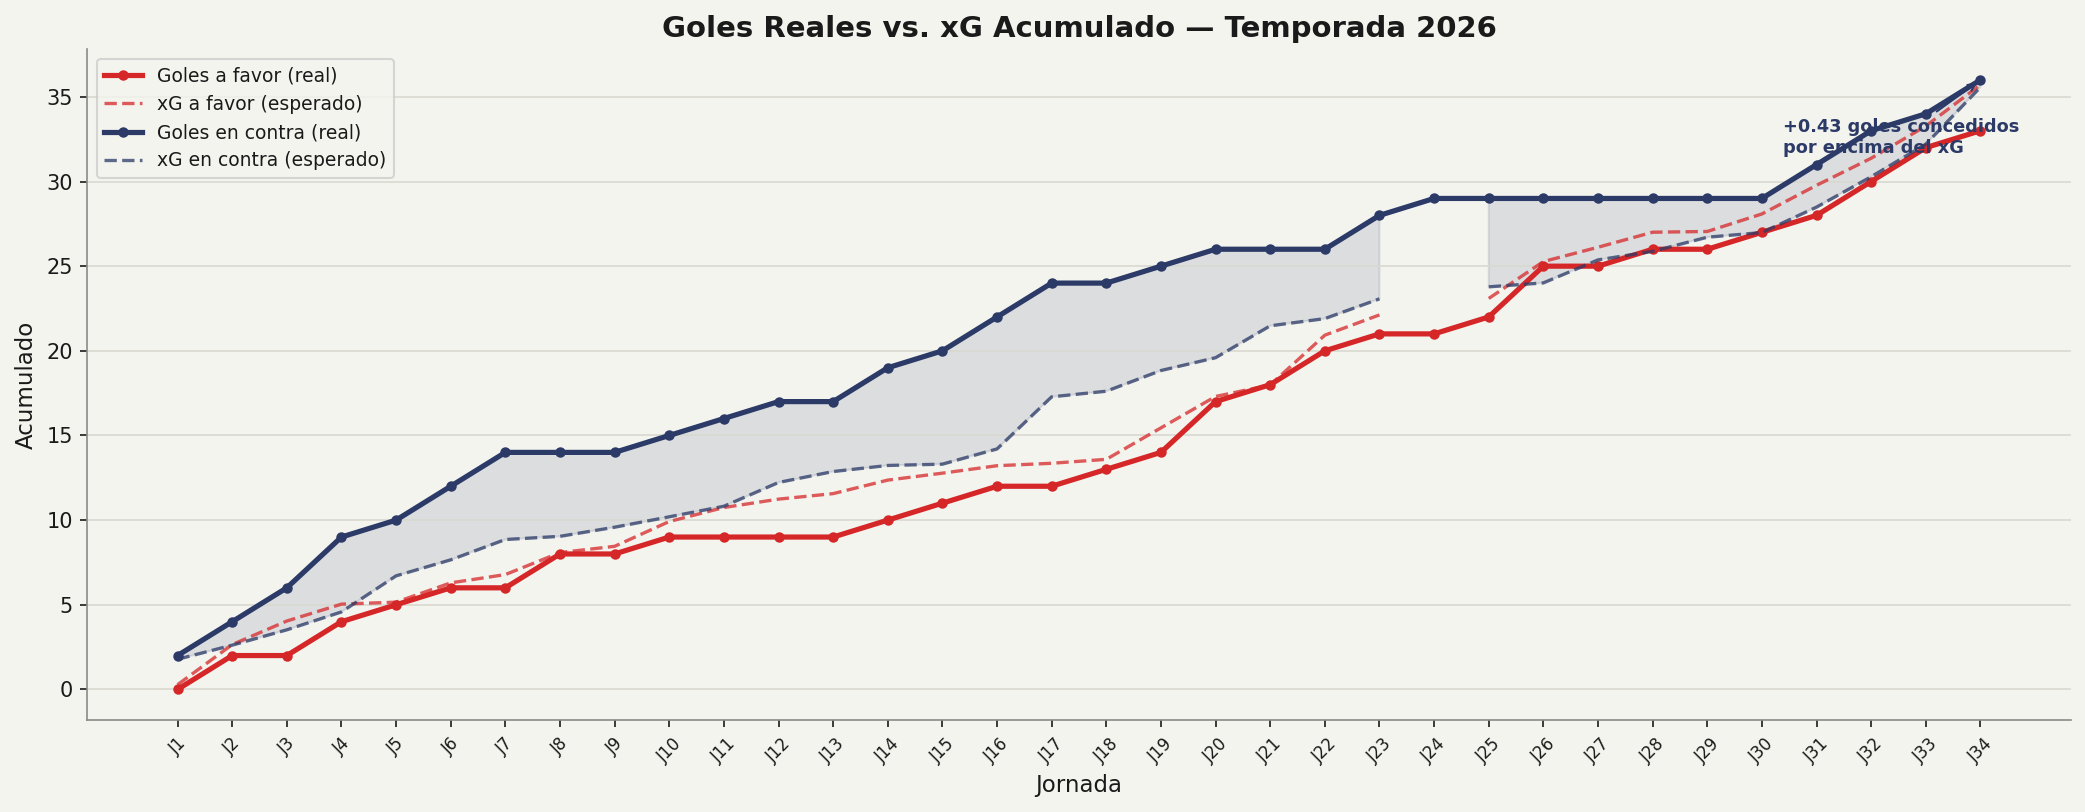

✅ evolution_xg_acumulado.png


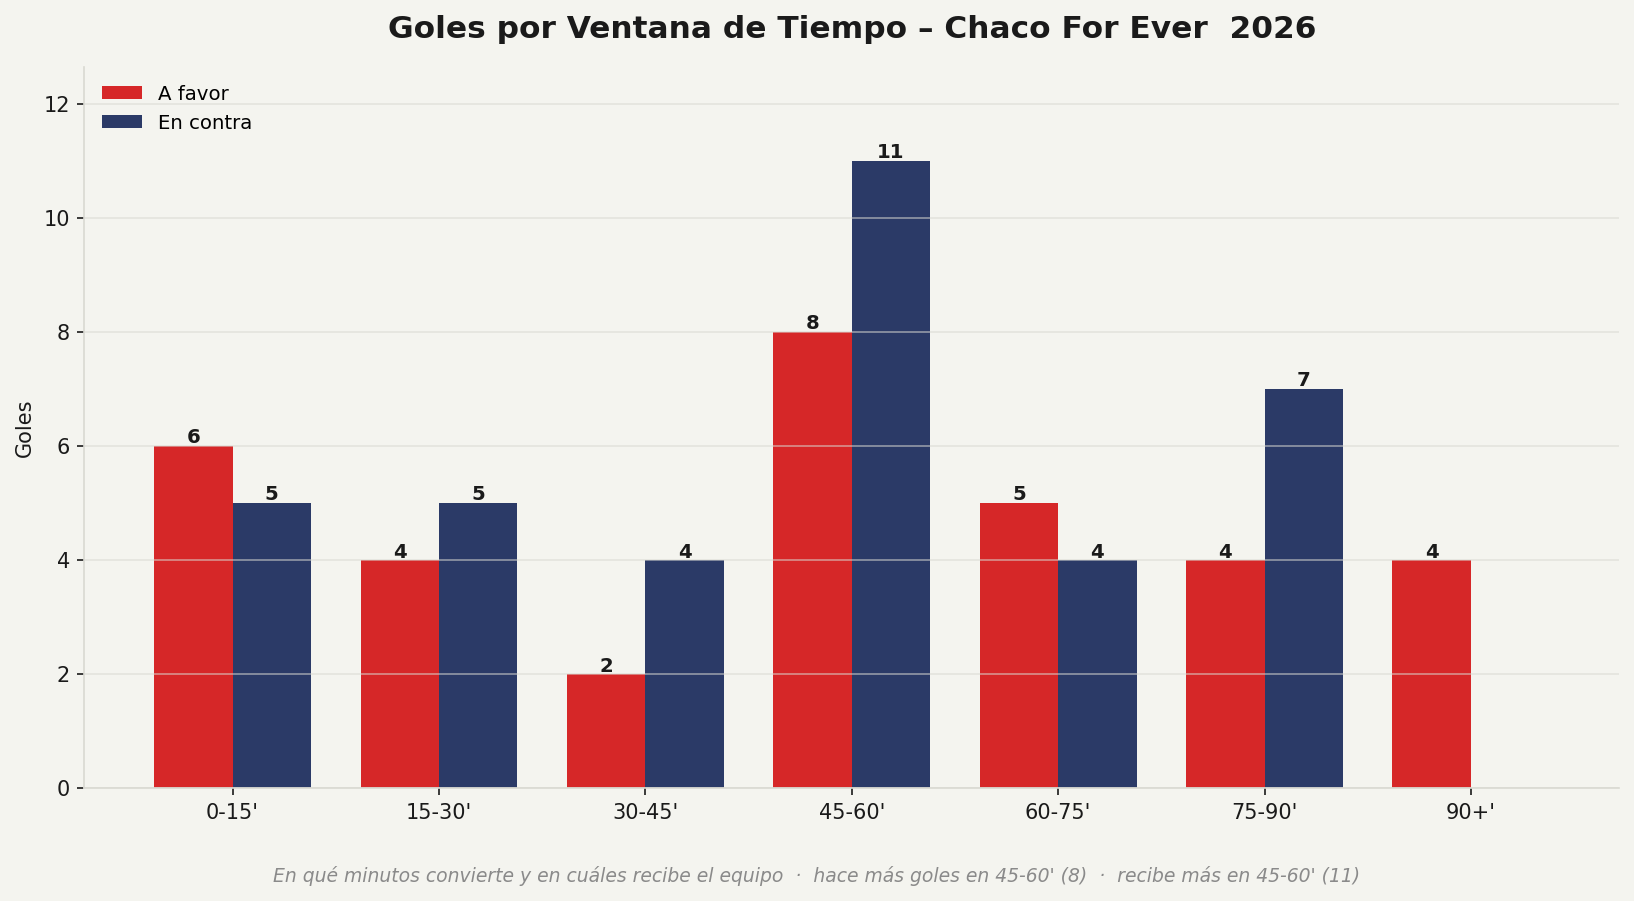

✅ goles_por_ventana_tiempo.png


In [8]:
# ── Gráficos que usa el informe de temporada en .tex ──────────────────────
# (los nombres de archivo tienen que coincidir con los \includegraphics del
#  Informe_temporada_*.tex: evolution_xg_acumulado.png y goles_por_ventana_tiempo.png)
from src.analysis.season import goals_by_time_window
from src.visualization.season import (
    plot_cumulative_xg_vs_goals, plot_goals_by_time_window,
)

# Goles reales acumulados (a favor / en contra) vs xG acumulado, fecha a fecha.
fig = plot_cumulative_xg_vs_goals(season_df)
if fig:
    save_fig(fig, os.path.join(PLOTS_DIR, 'evolution_xg_acumulado.png'))
    show(os.path.join(PLOTS_DIR, 'evolution_xg_acumulado.png'))
    print('✅ evolution_xg_acumulado.png')

# En qué ventana de 15' convierte el equipo y en cuáles recibe.
gtw = goals_by_time_window(match_keys_with_data, BASE_DIR)
if gtw is not None and not gtw.empty:
    fig = plot_goals_by_time_window(gtw, season=SEASON)
    if fig:
        save_fig(fig, os.path.join(PLOTS_DIR, 'goles_por_ventana_tiempo.png'))
        show(os.path.join(PLOTS_DIR, 'goles_por_ventana_tiempo.png'))
        print('✅ goles_por_ventana_tiempo.png')


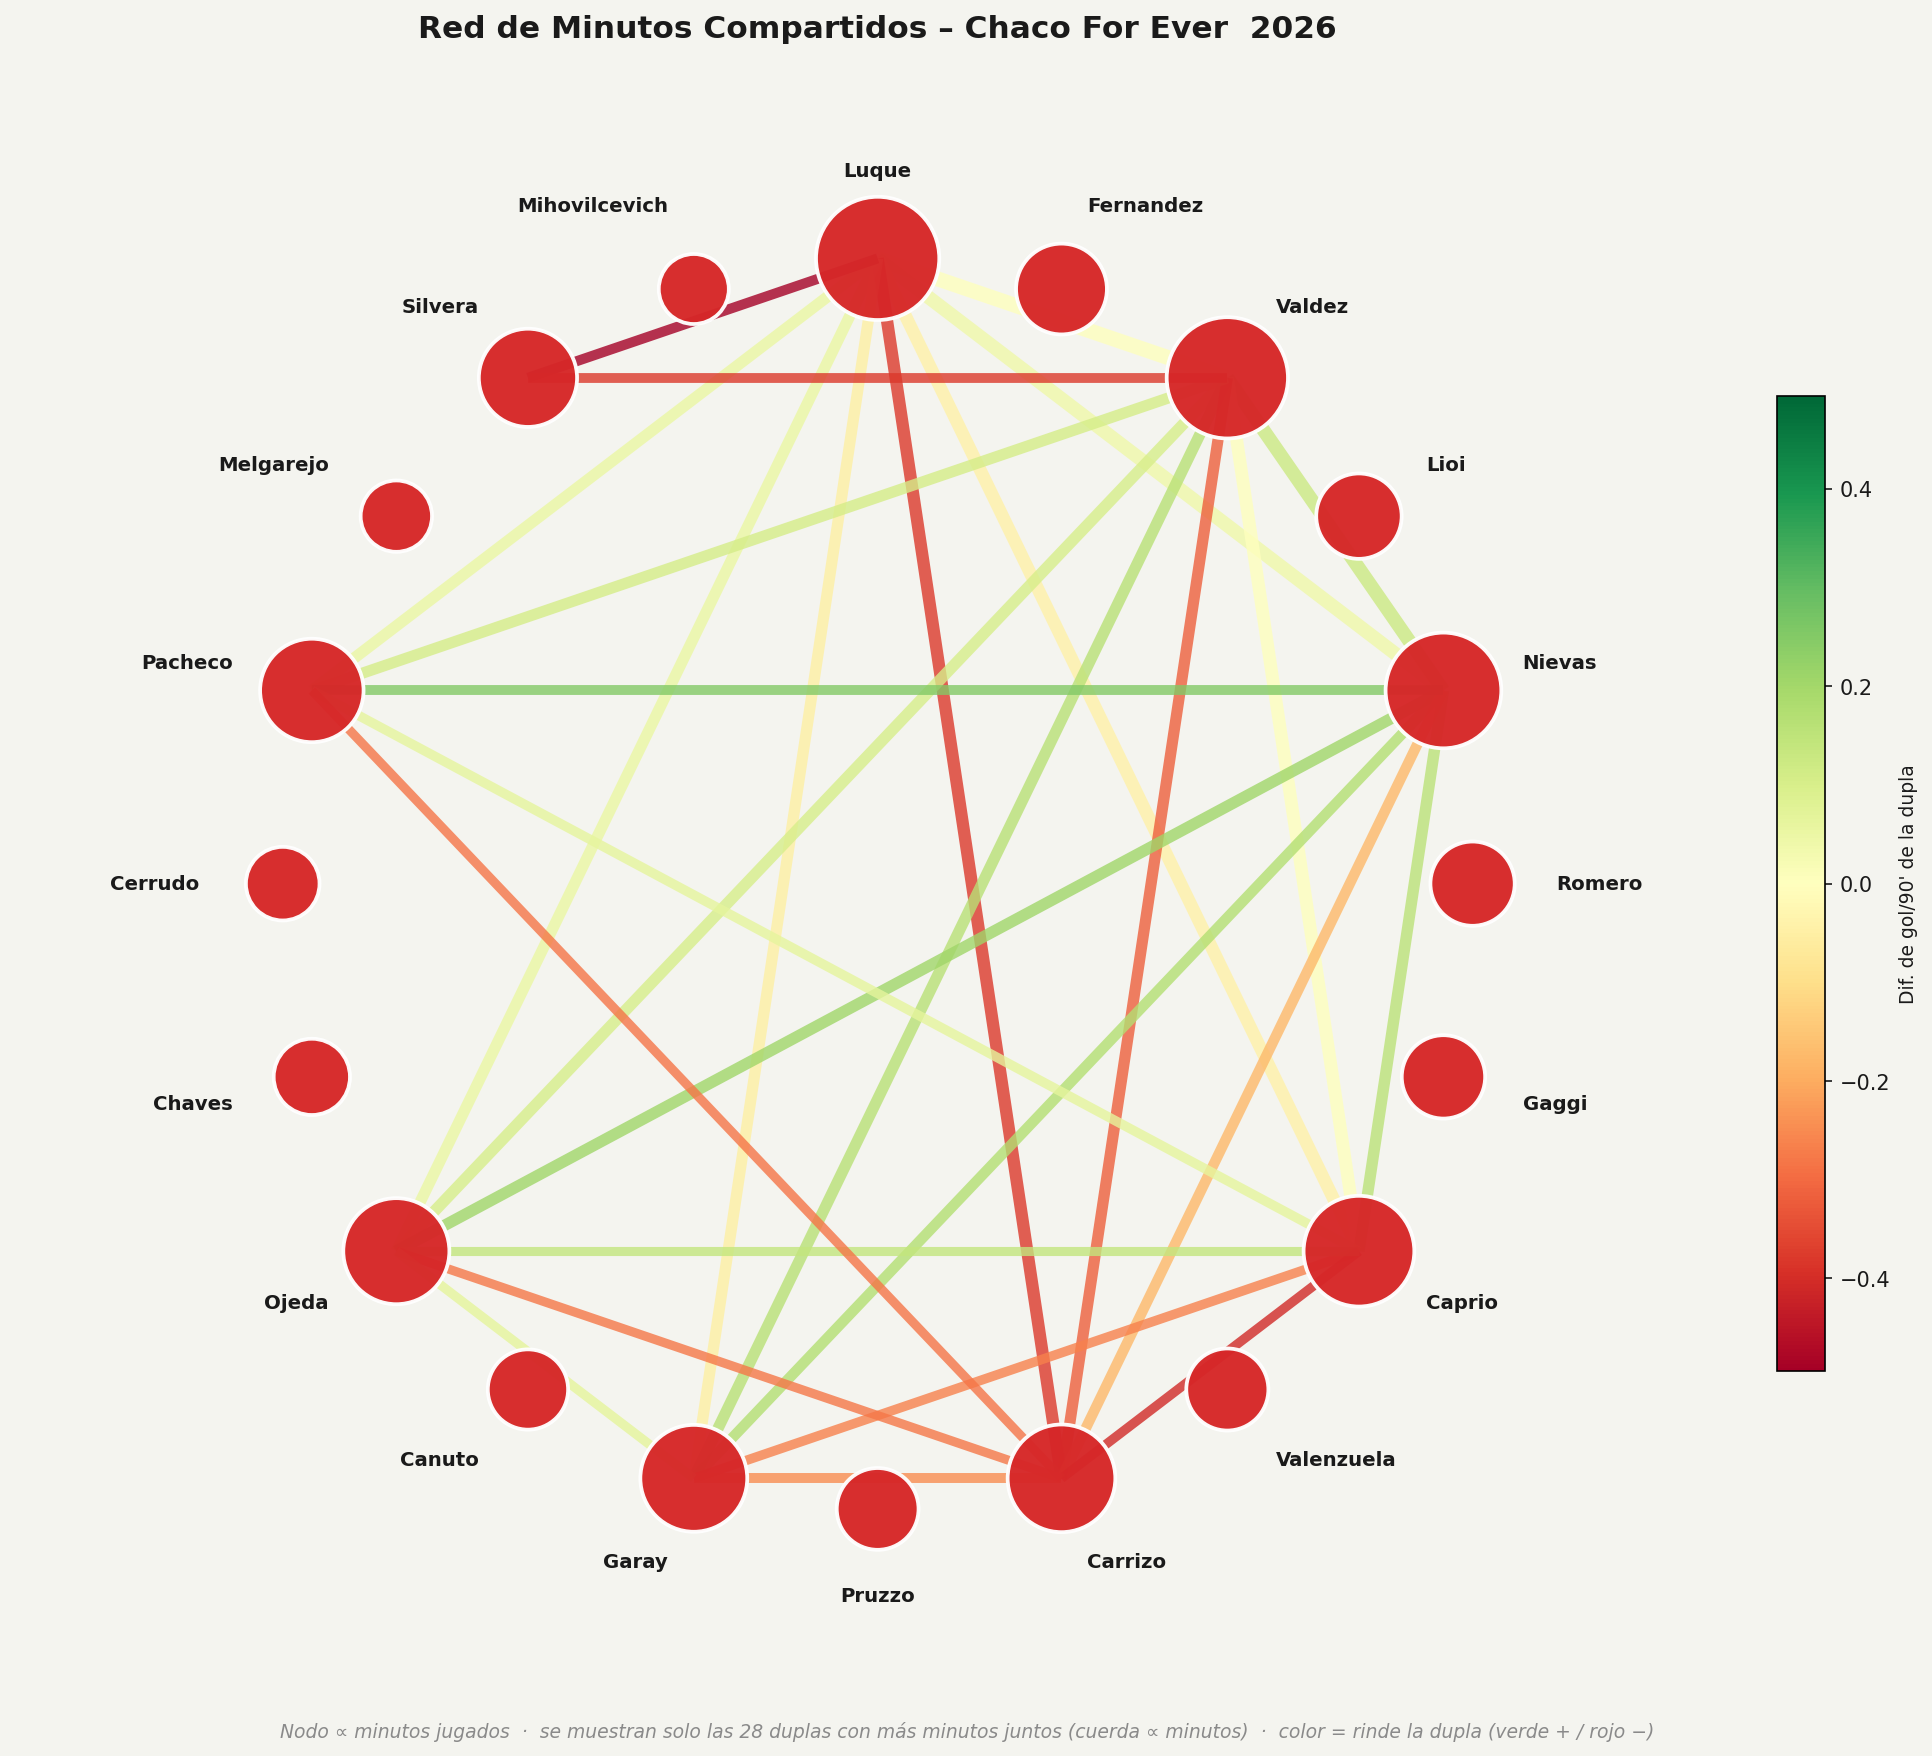

✅ red_minutos_compartidos.png  (20 jugadores, 190 duplas)
   incorporaciones en la red: E. Gaggi, G. Melgarejo, J. Carrizo, L. Fernandez, L. Mihovilcevich, M. D. Chaves, M. S. Romero


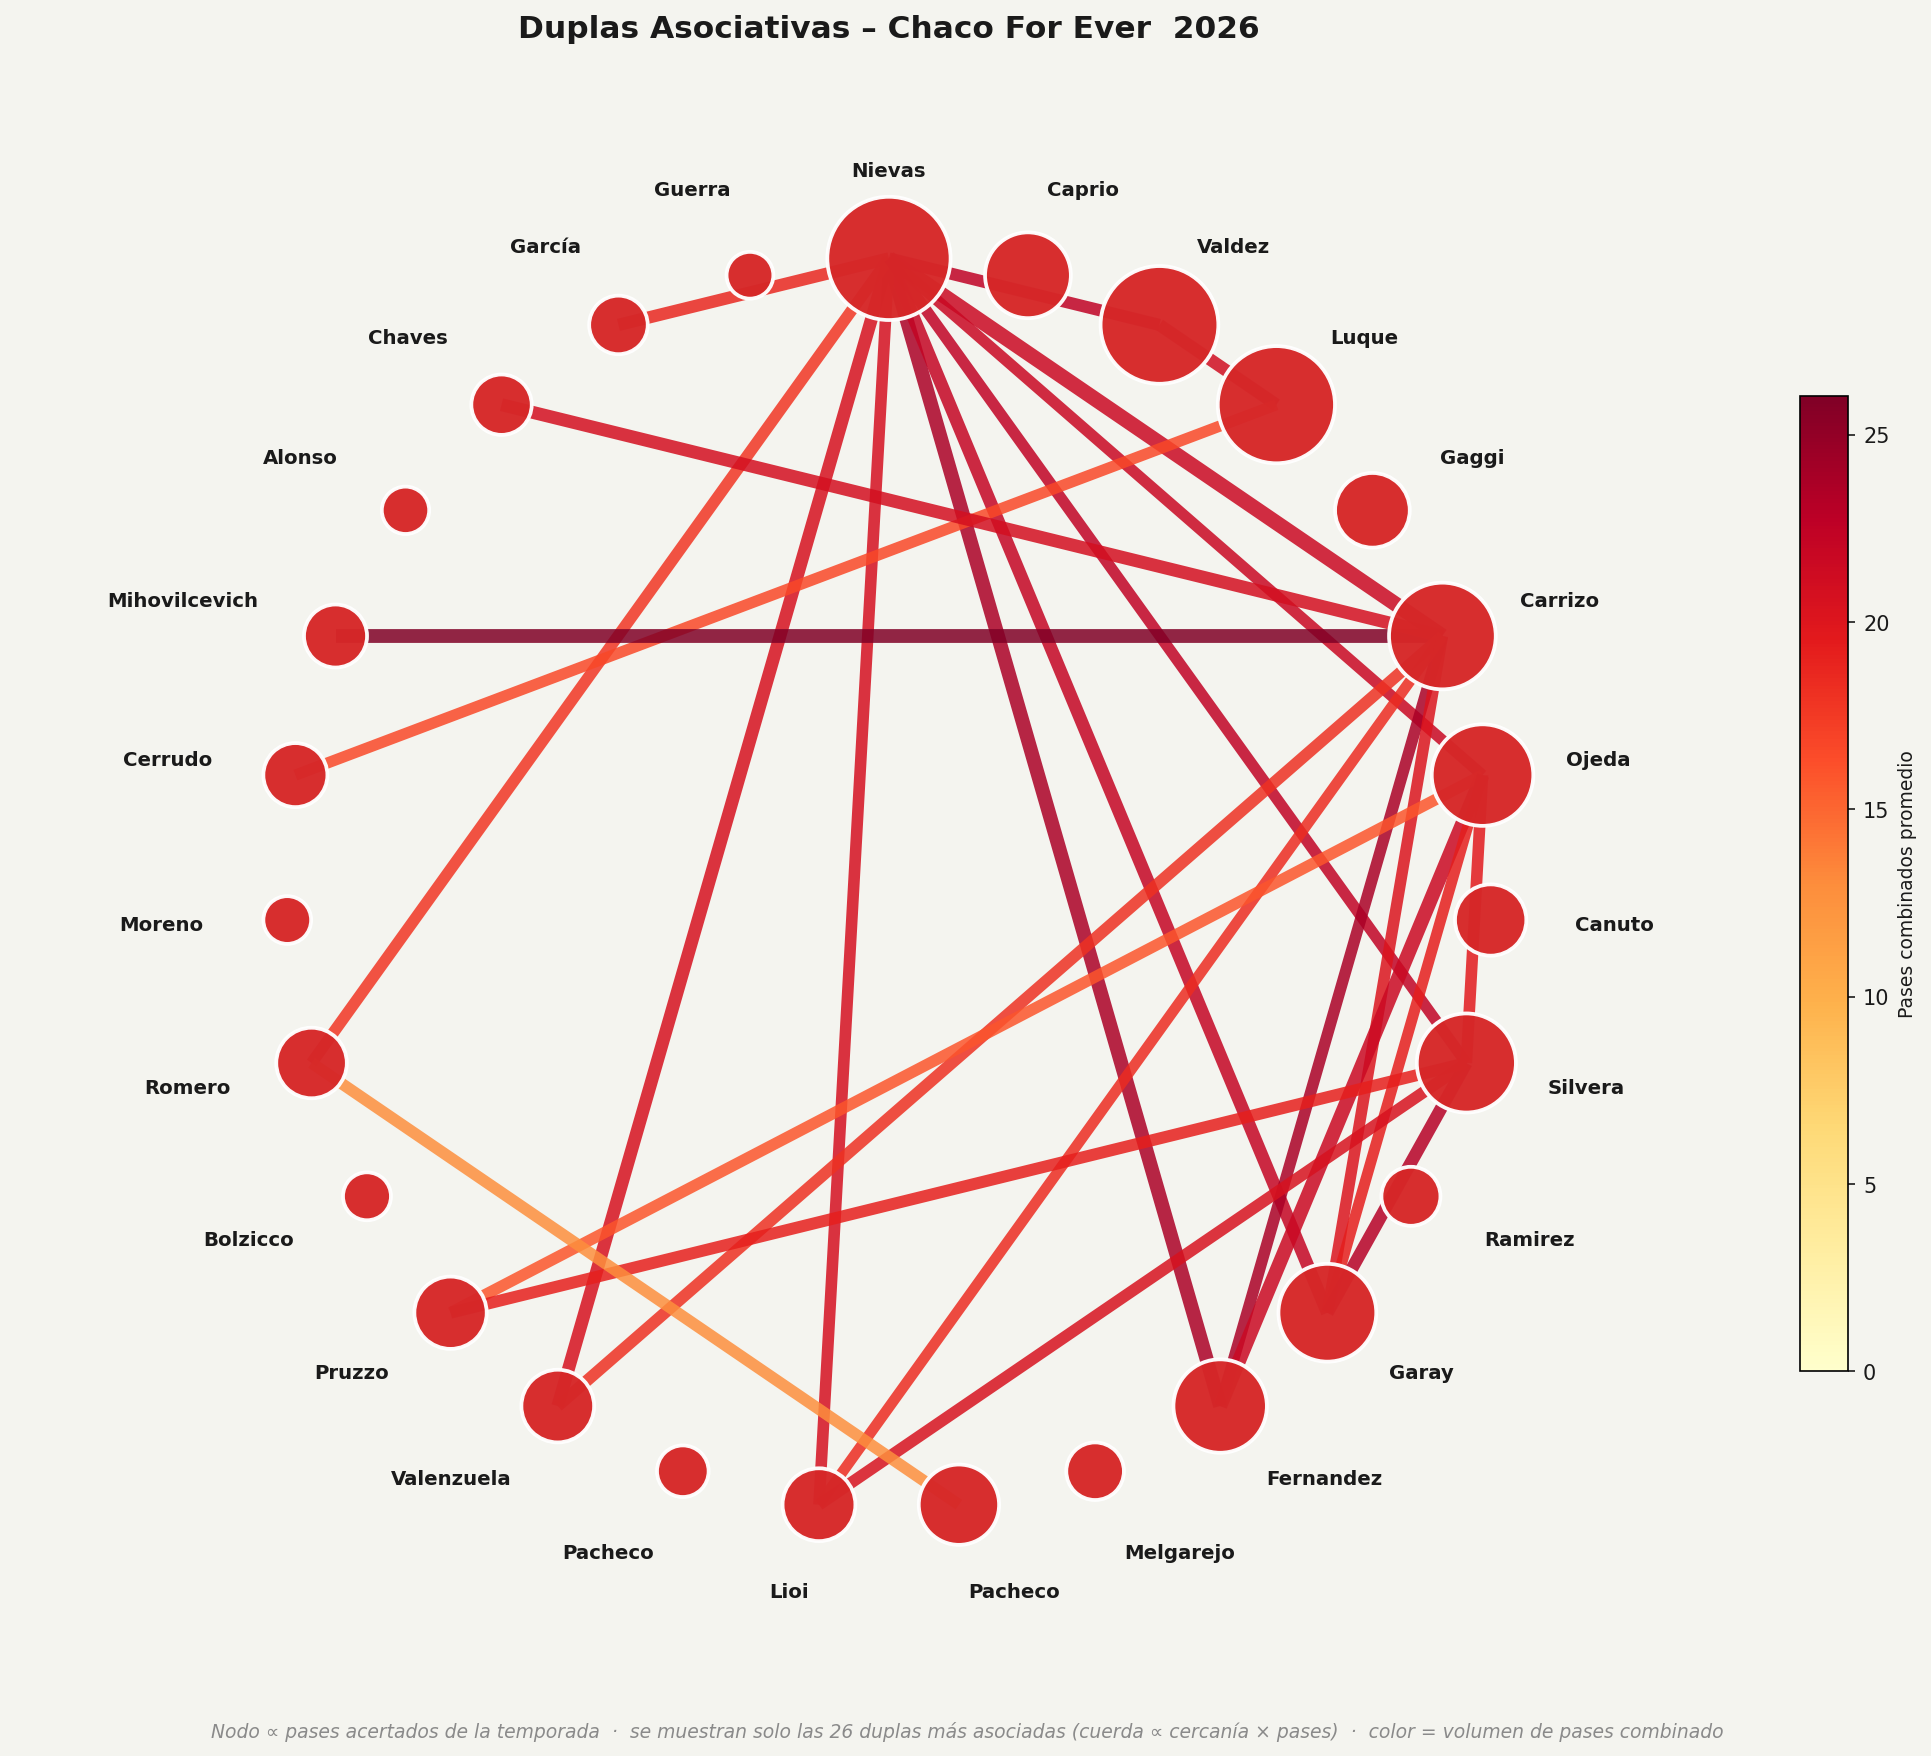

✅ duplas_asociativas.png  (27 jugadores, 135 duplas)


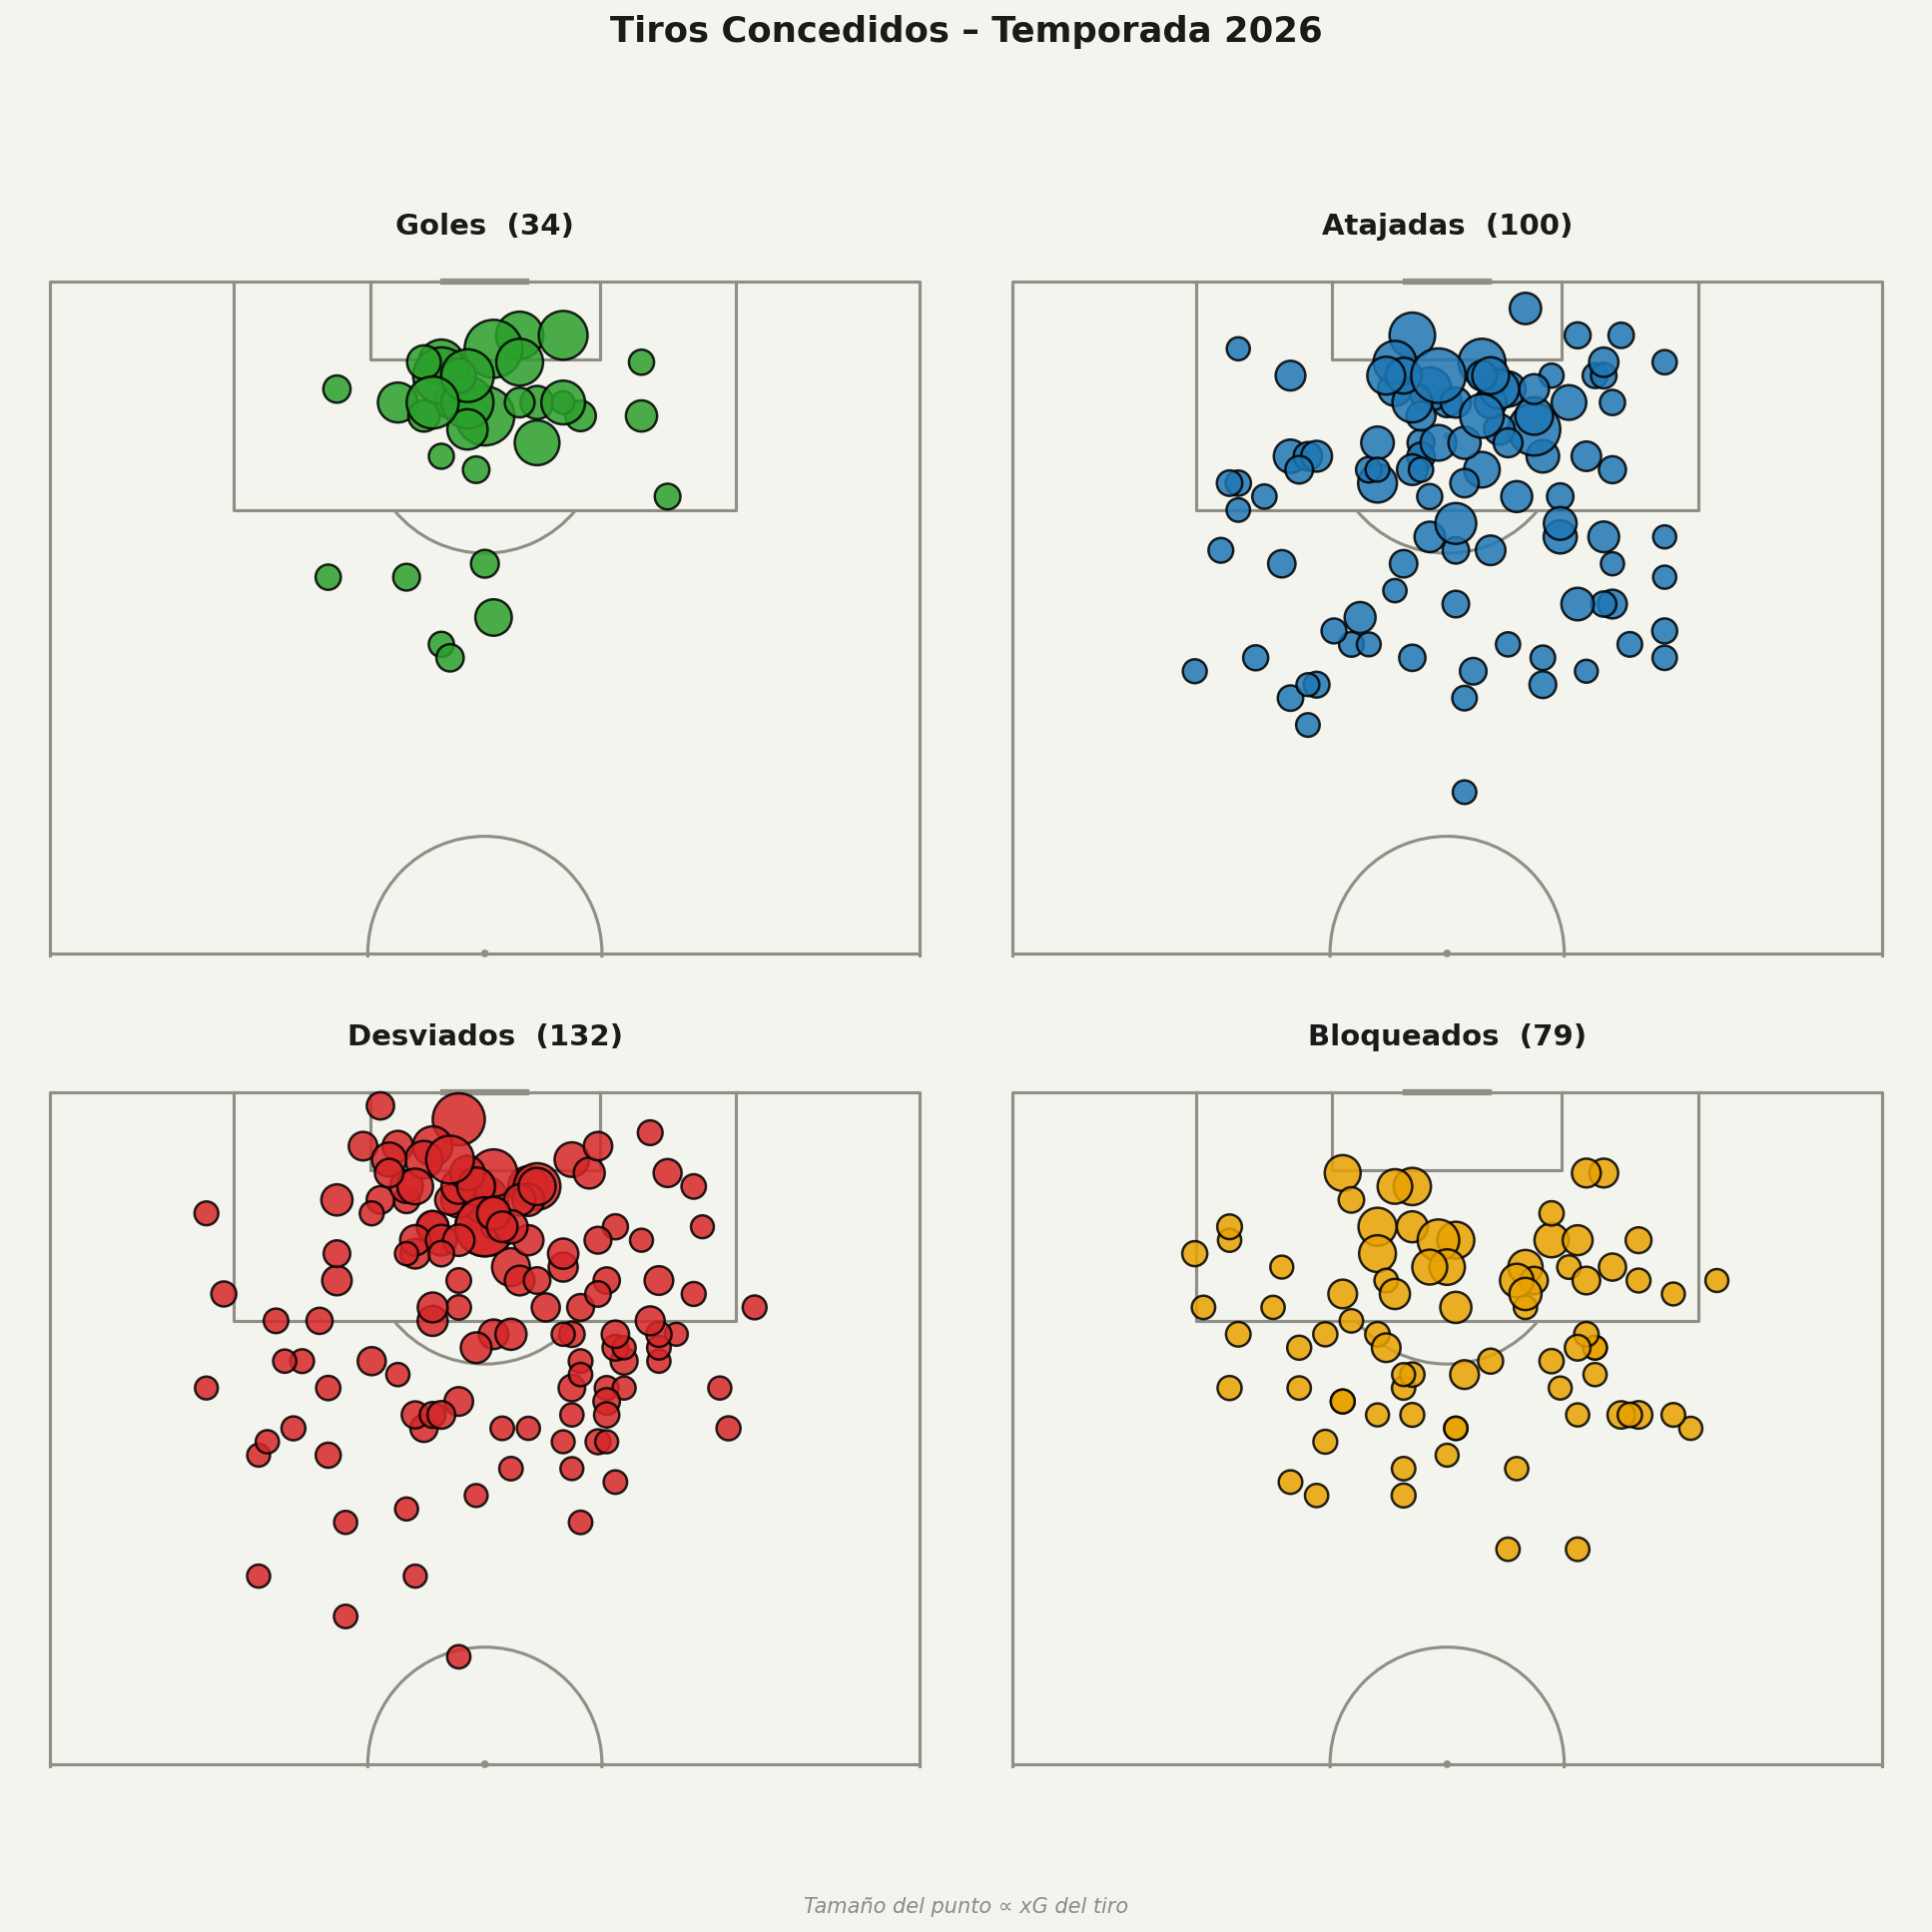

✅ tiros_concedidos_temporada.png


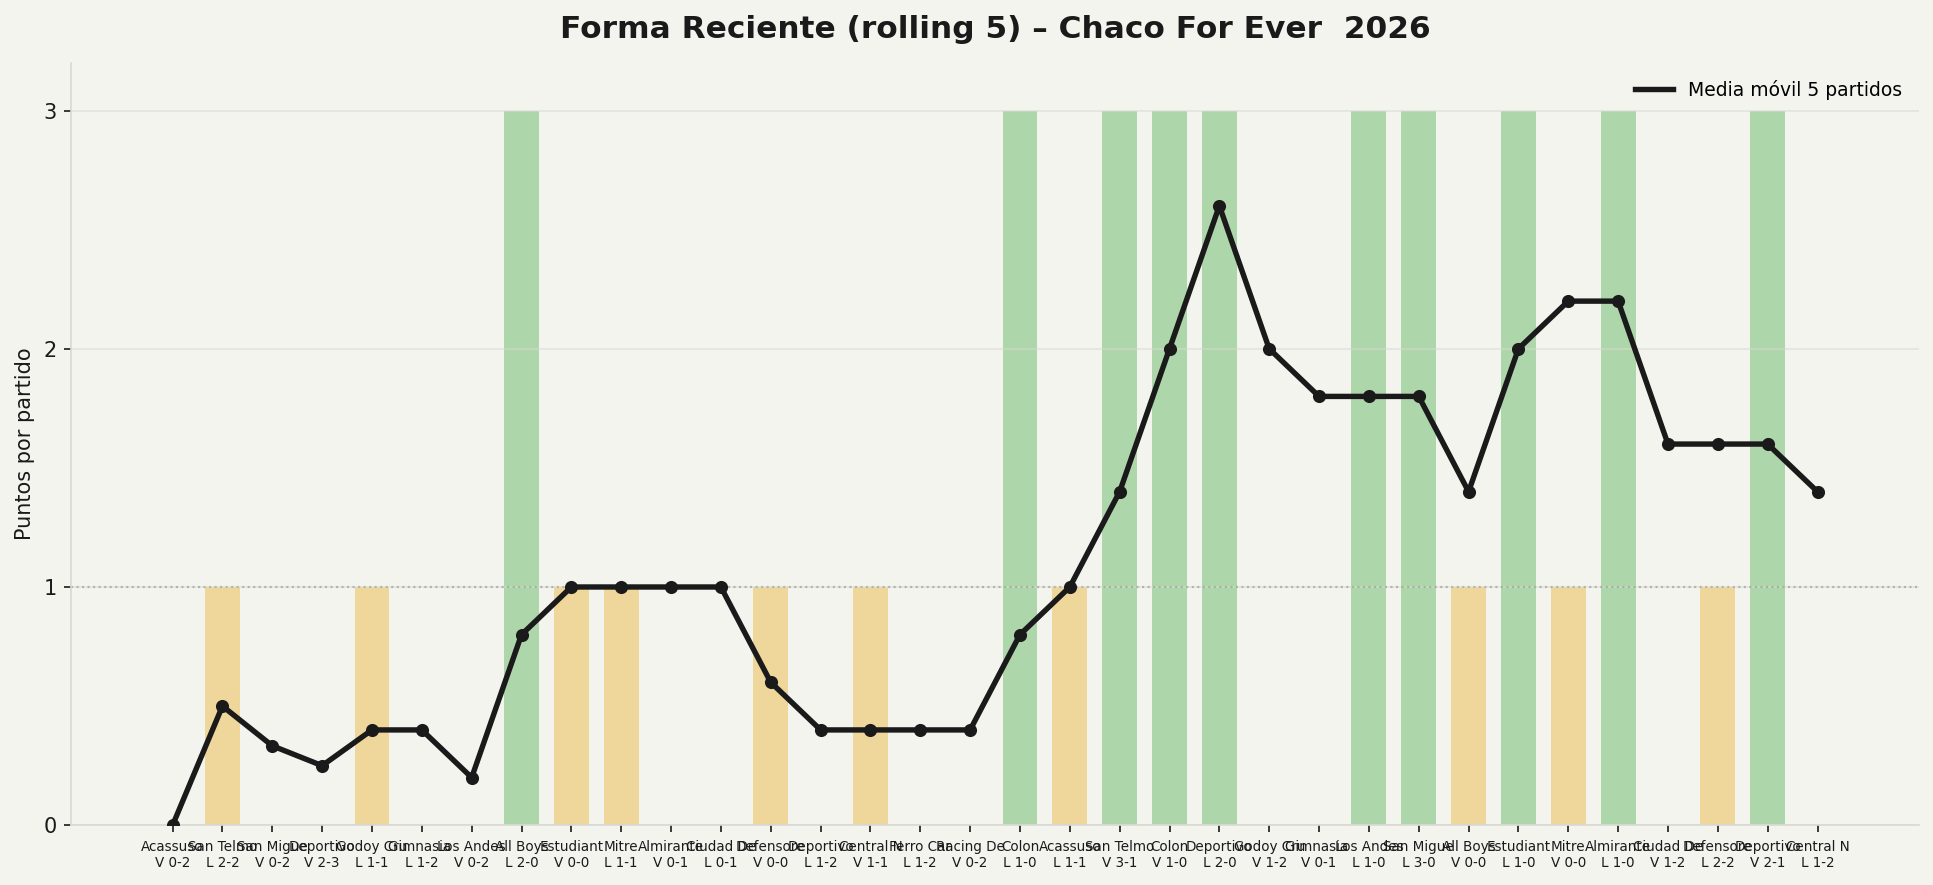

✅ forma_reciente.png


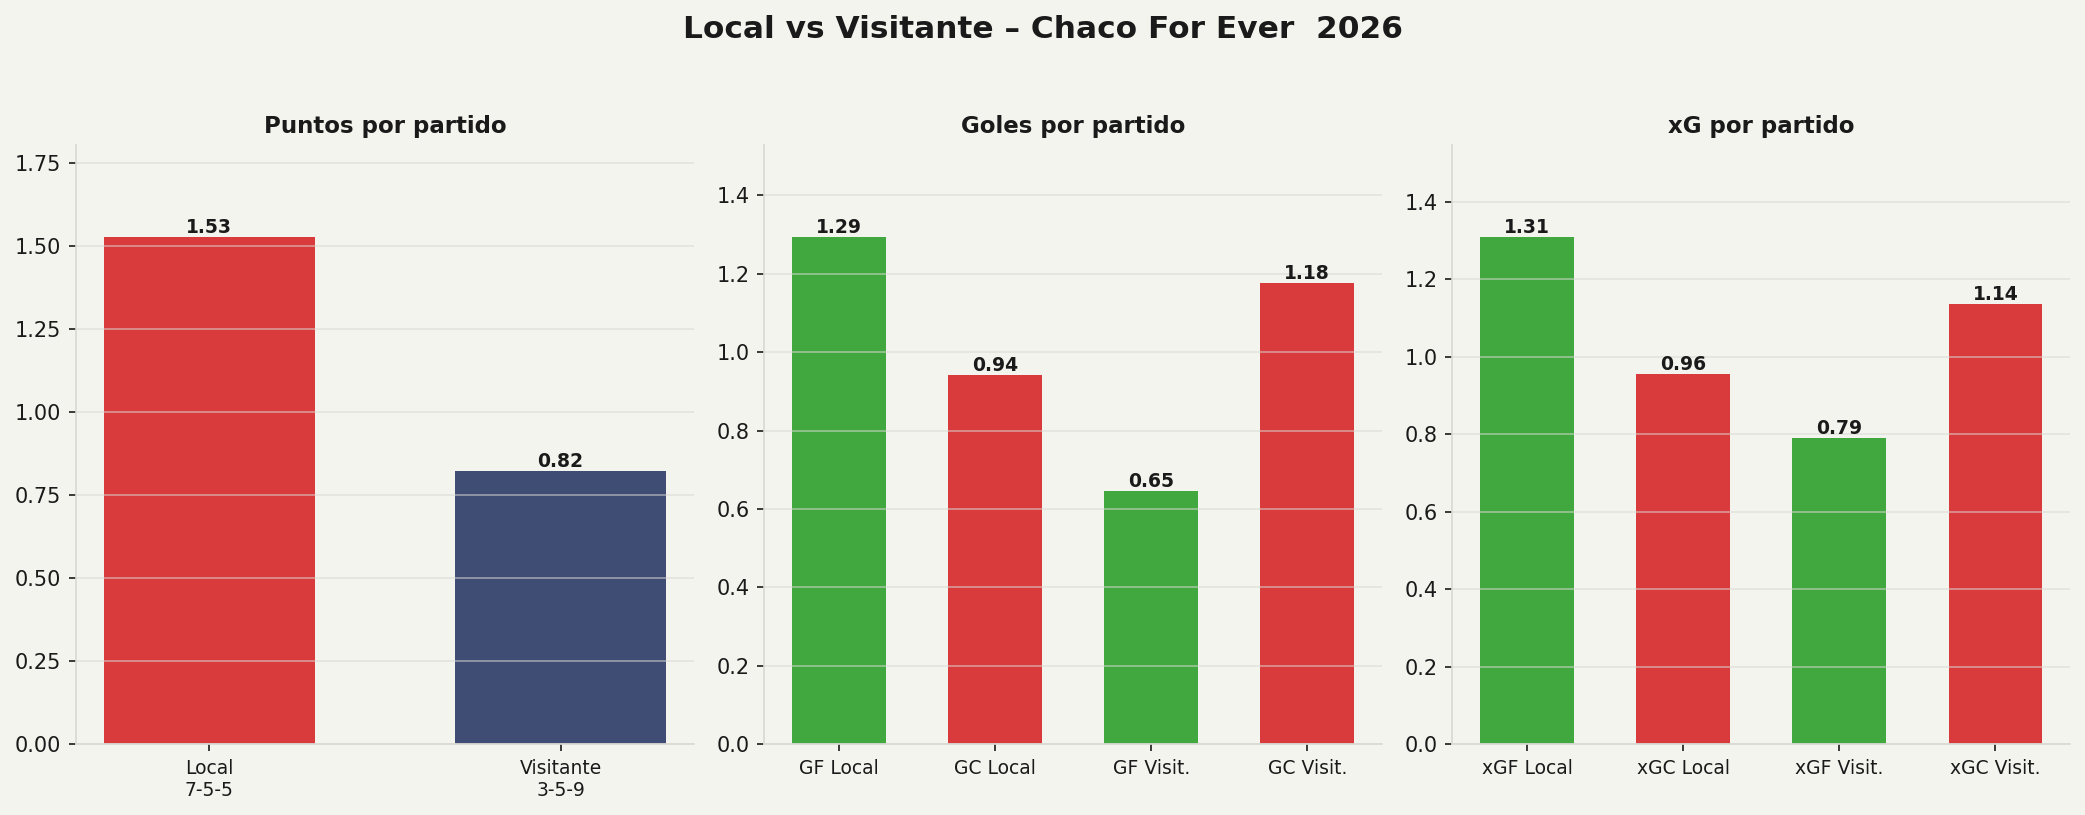

✅ local_vs_visitante.png


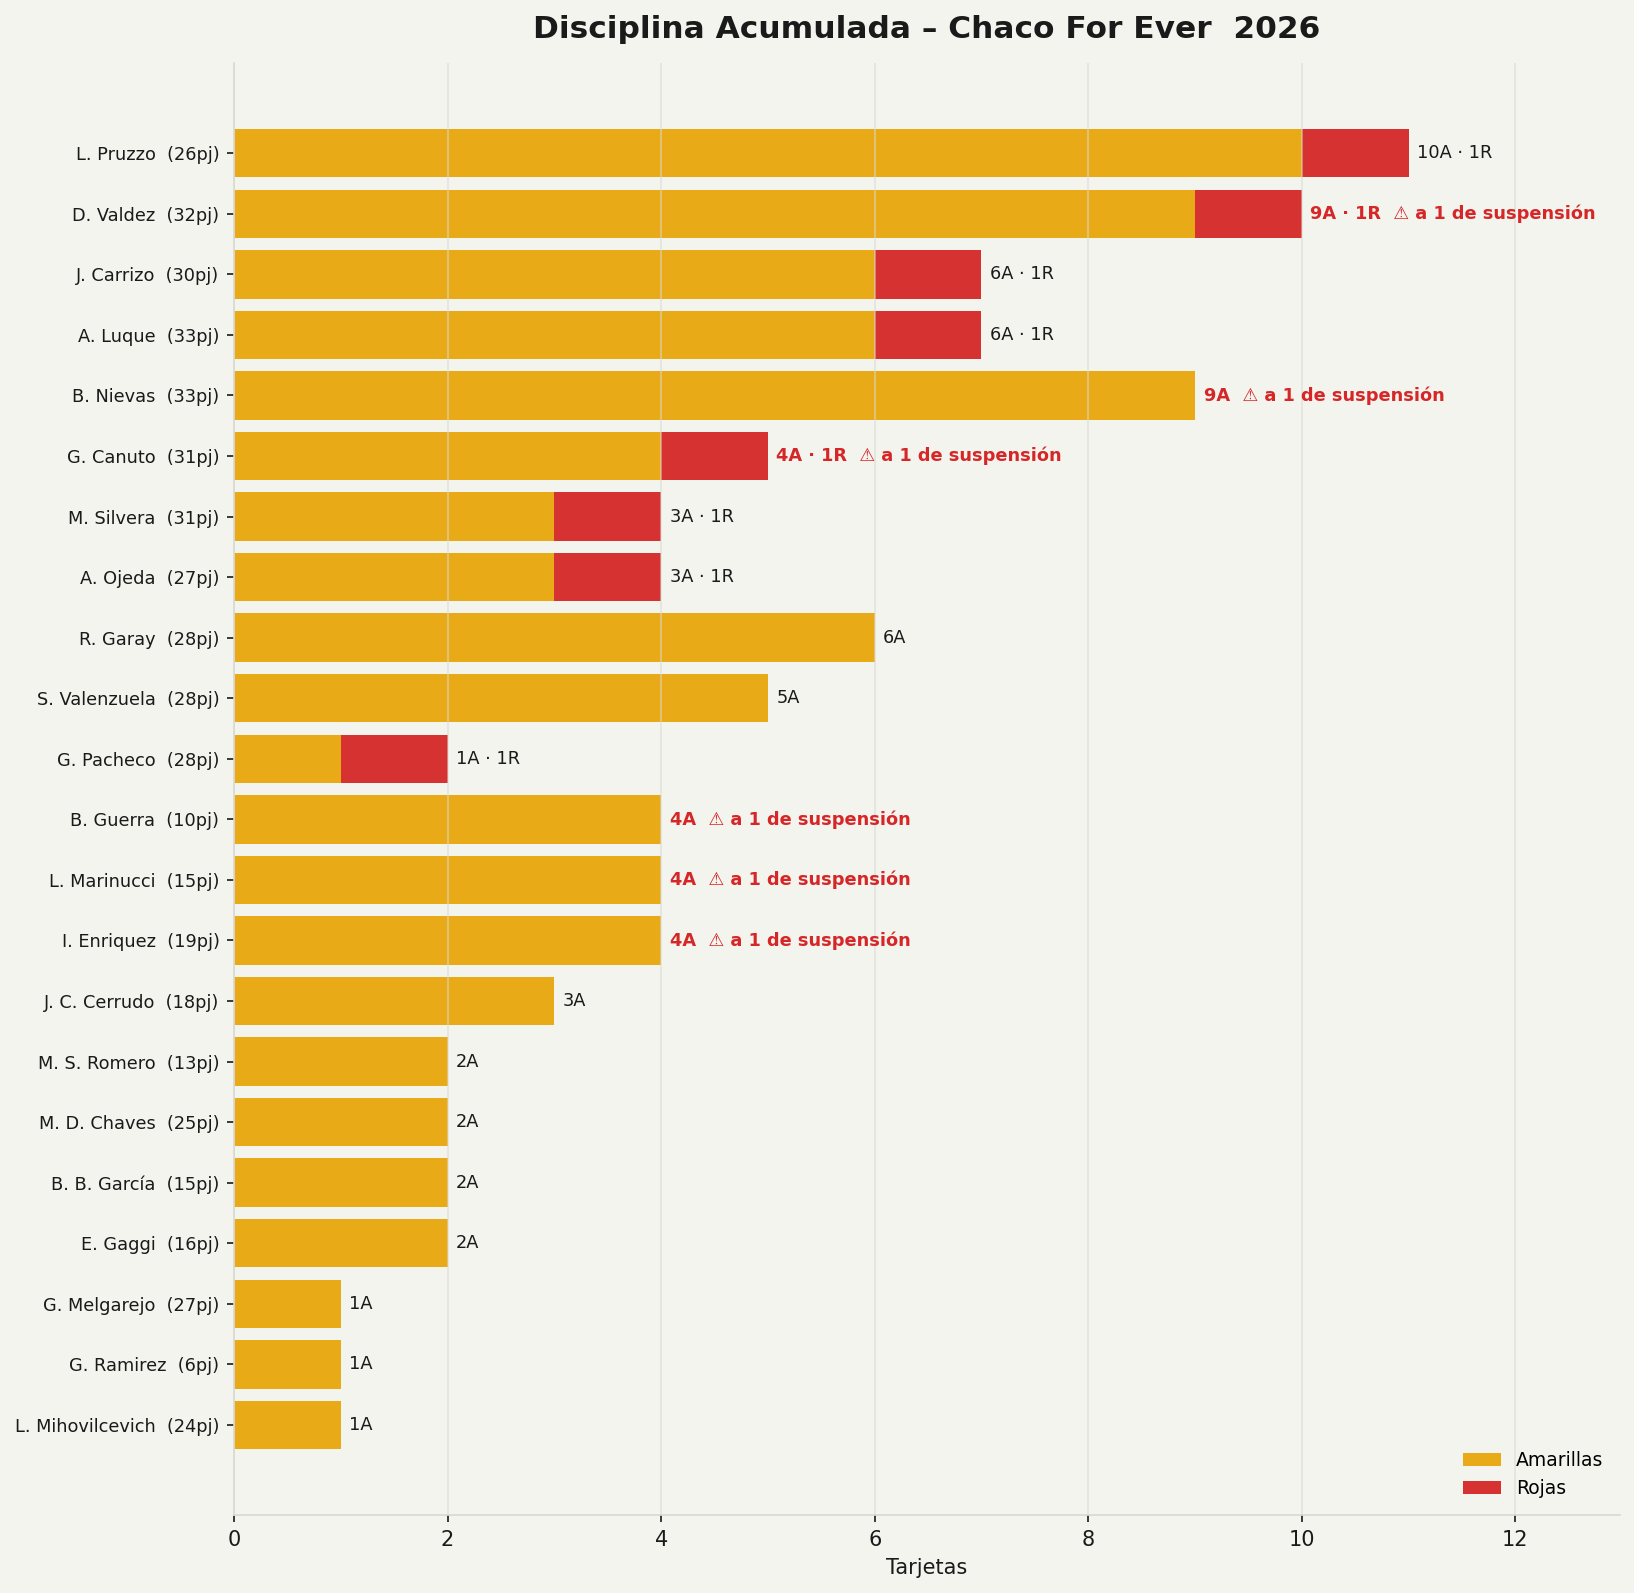

✅ disciplina.png


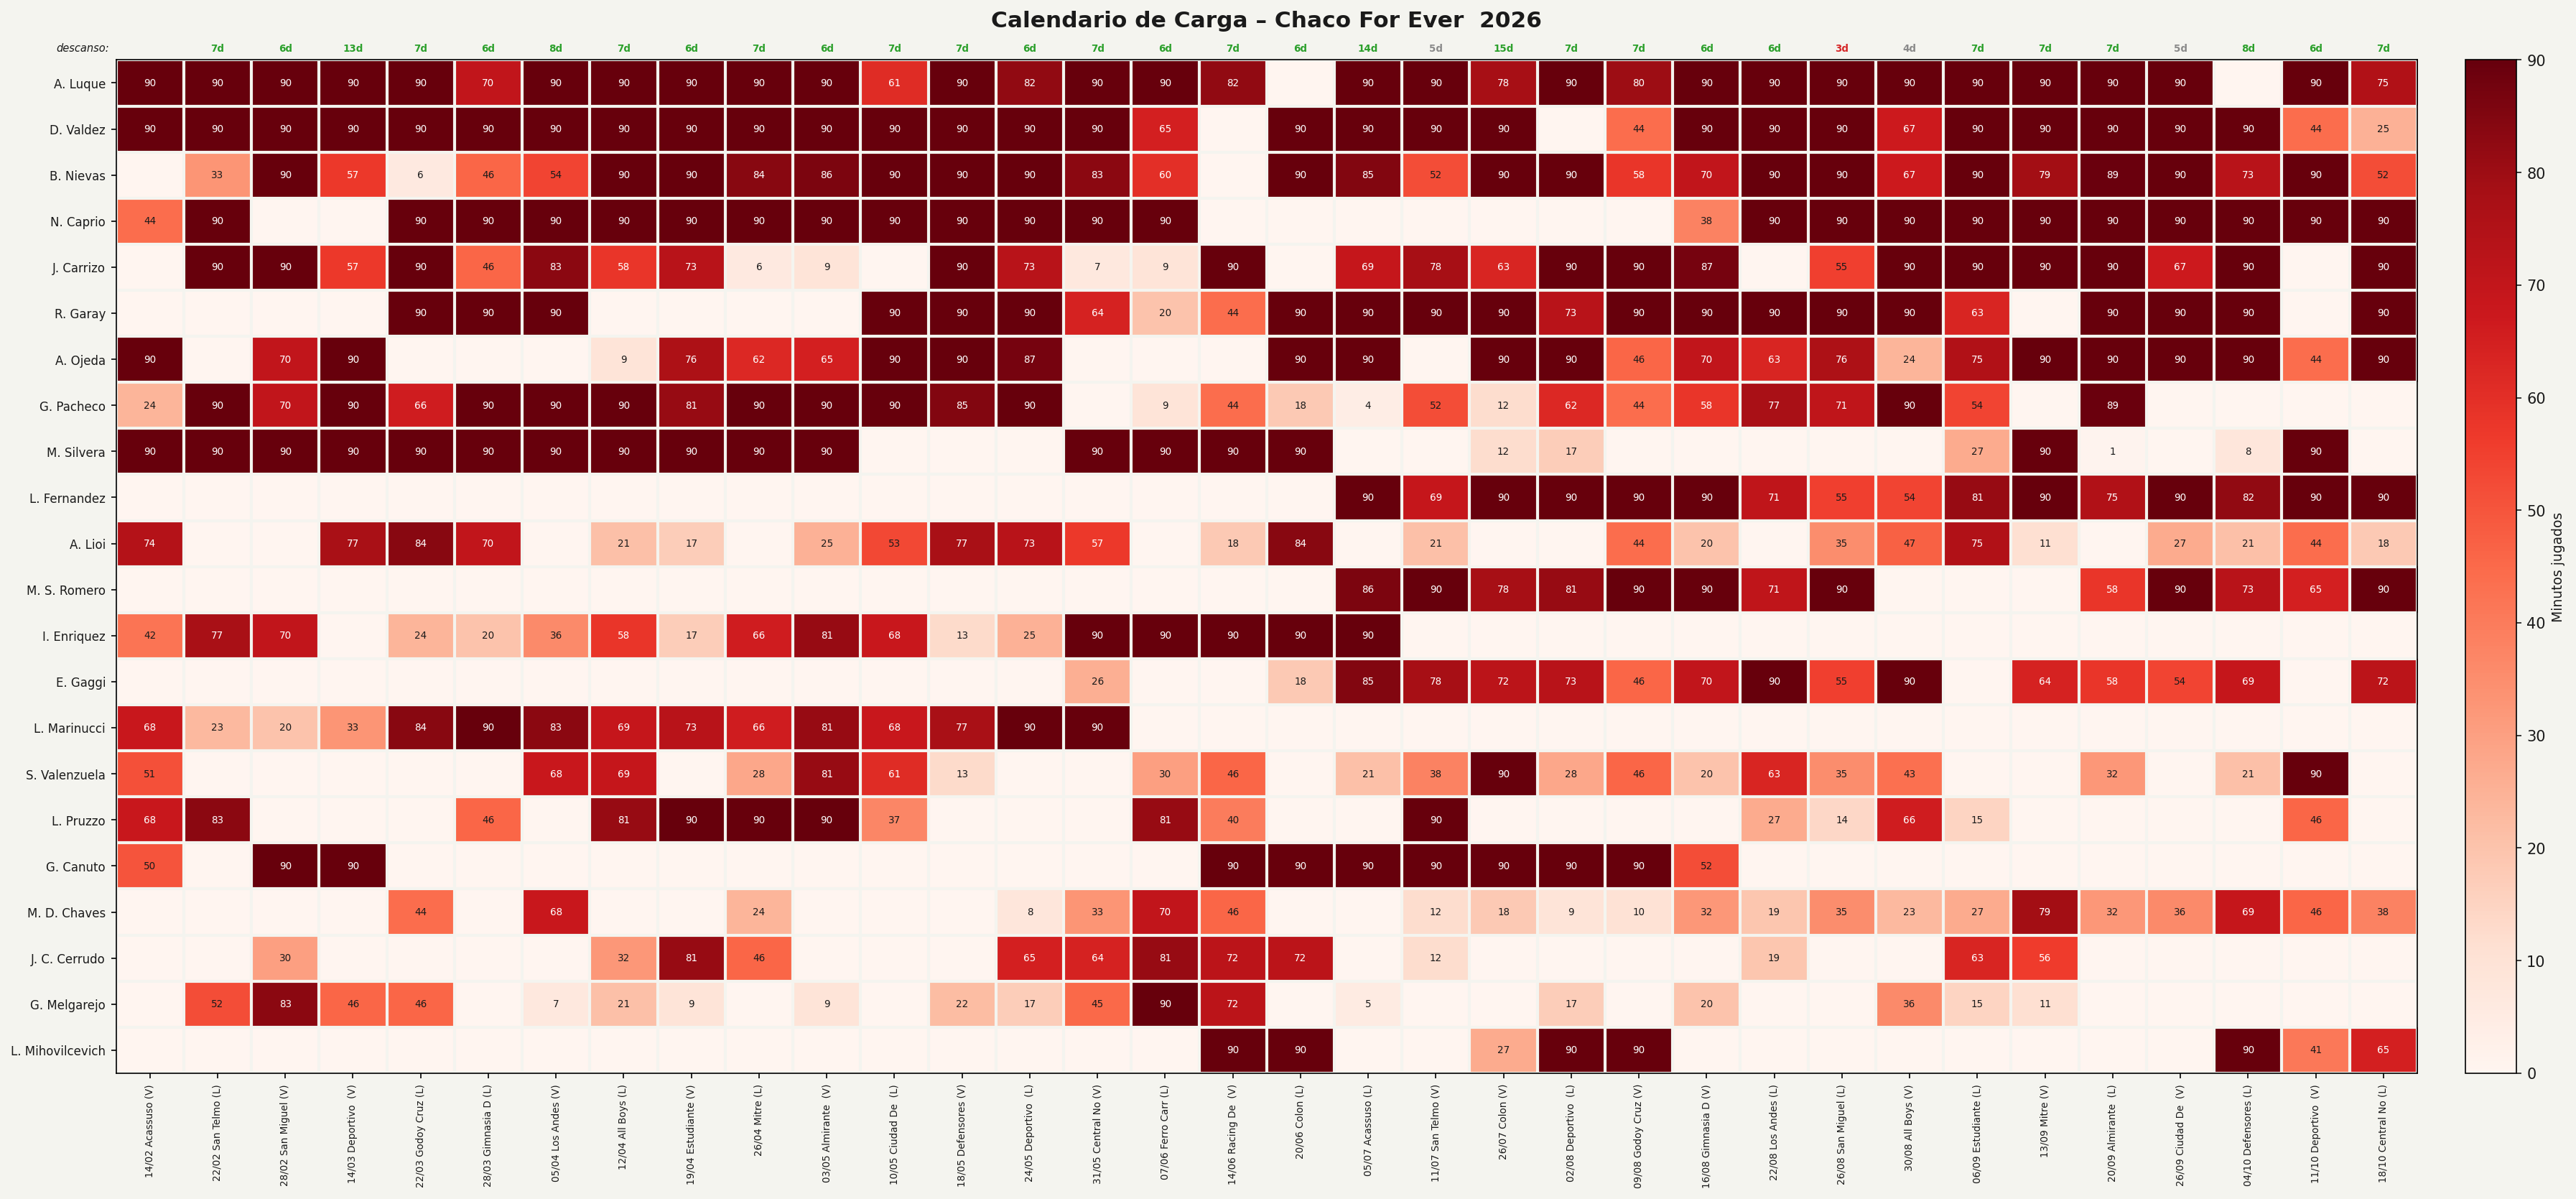

✅ calendario_carga.png  (22 jugadores)


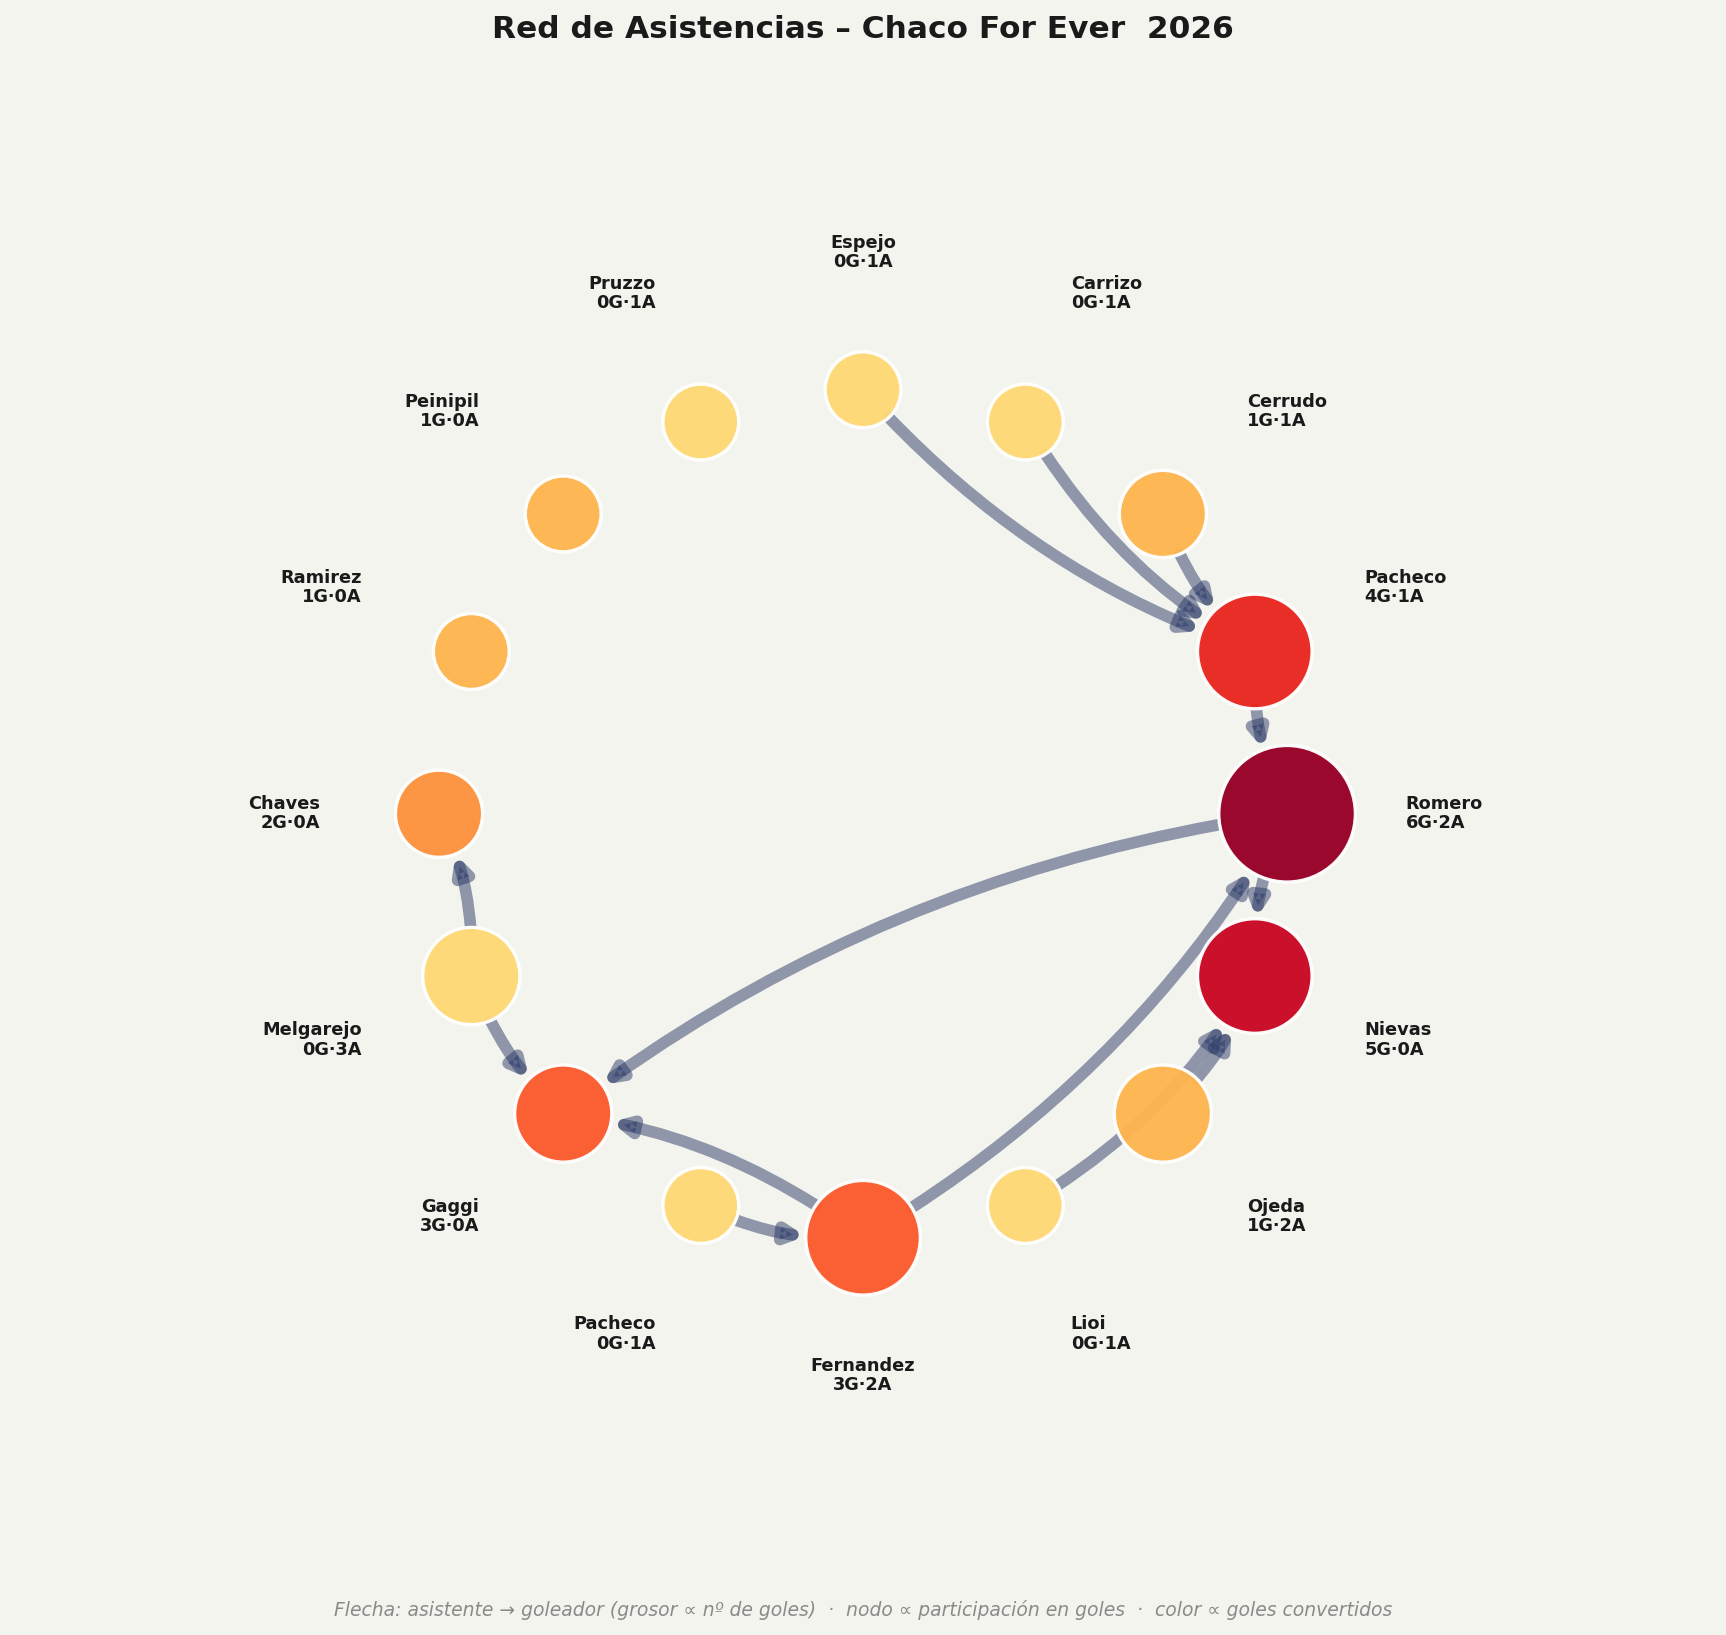

✅ red_asistencias.png  (16 jugadores, 13 conexiones)


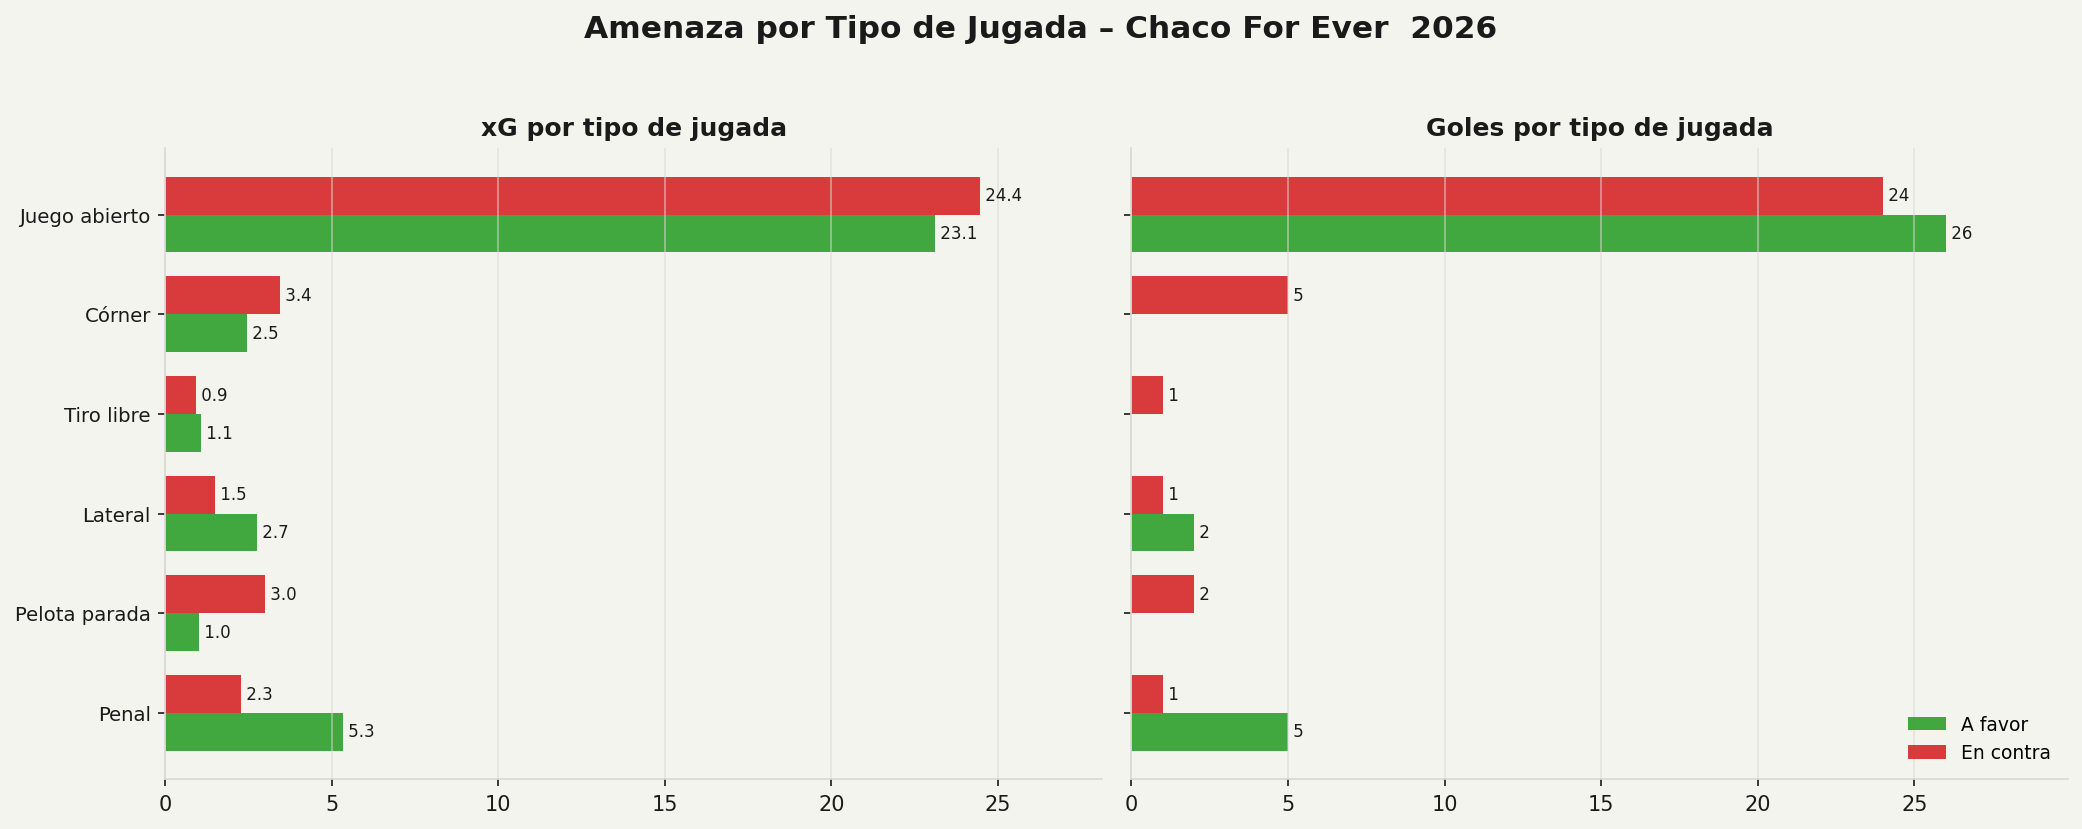

✅ amenaza_por_jugada.png


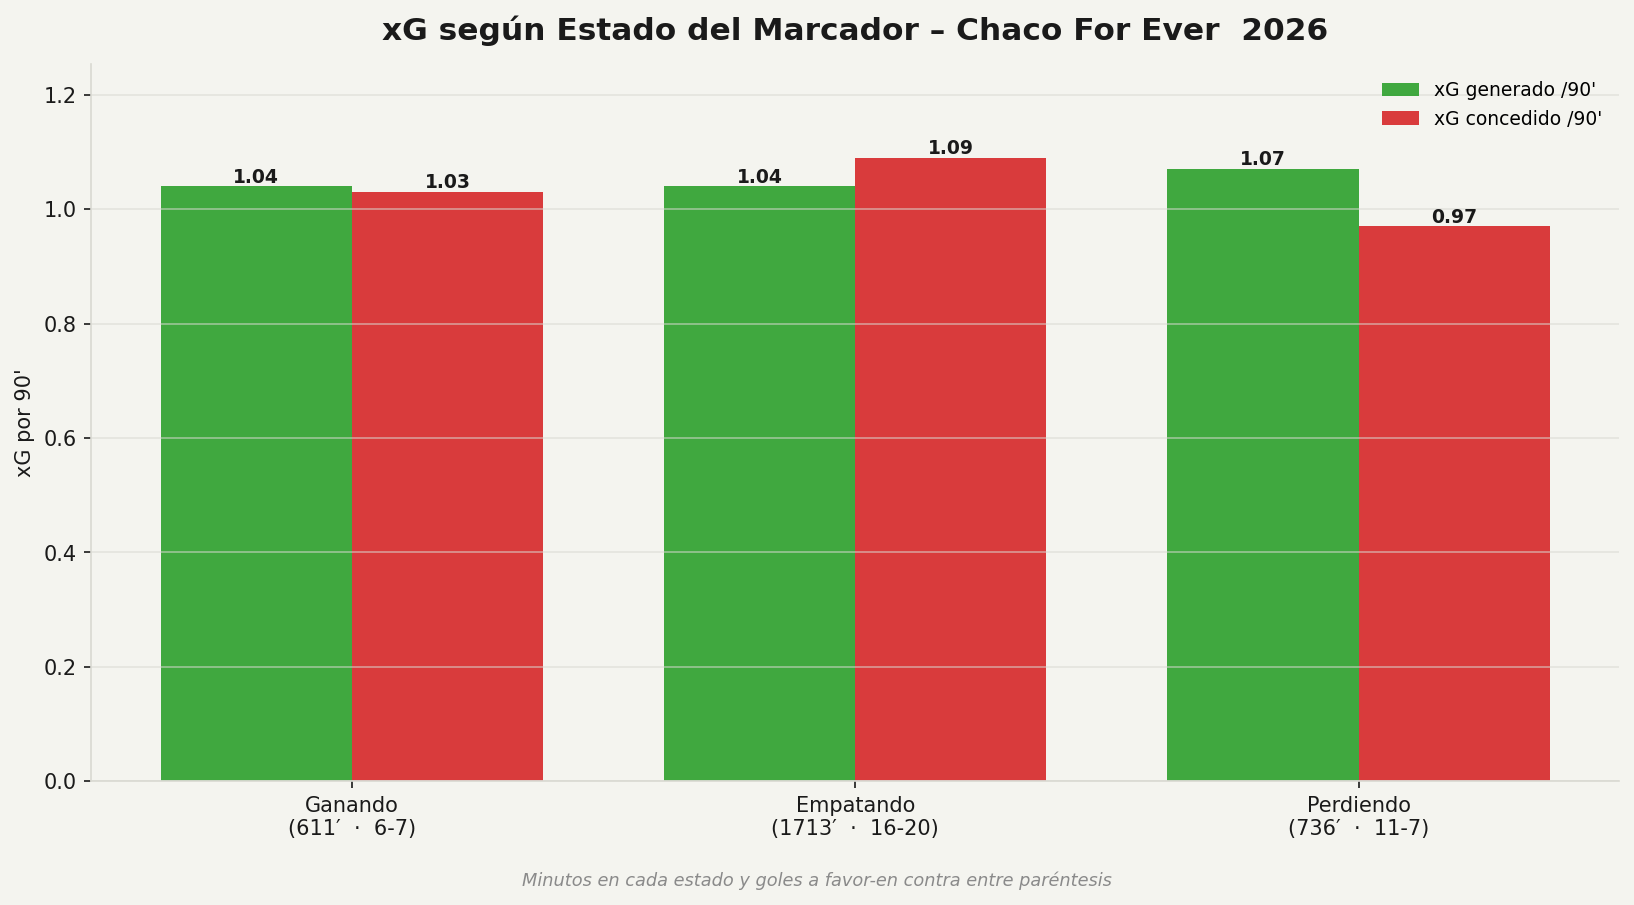

✅ xg_por_estado_marcador.png


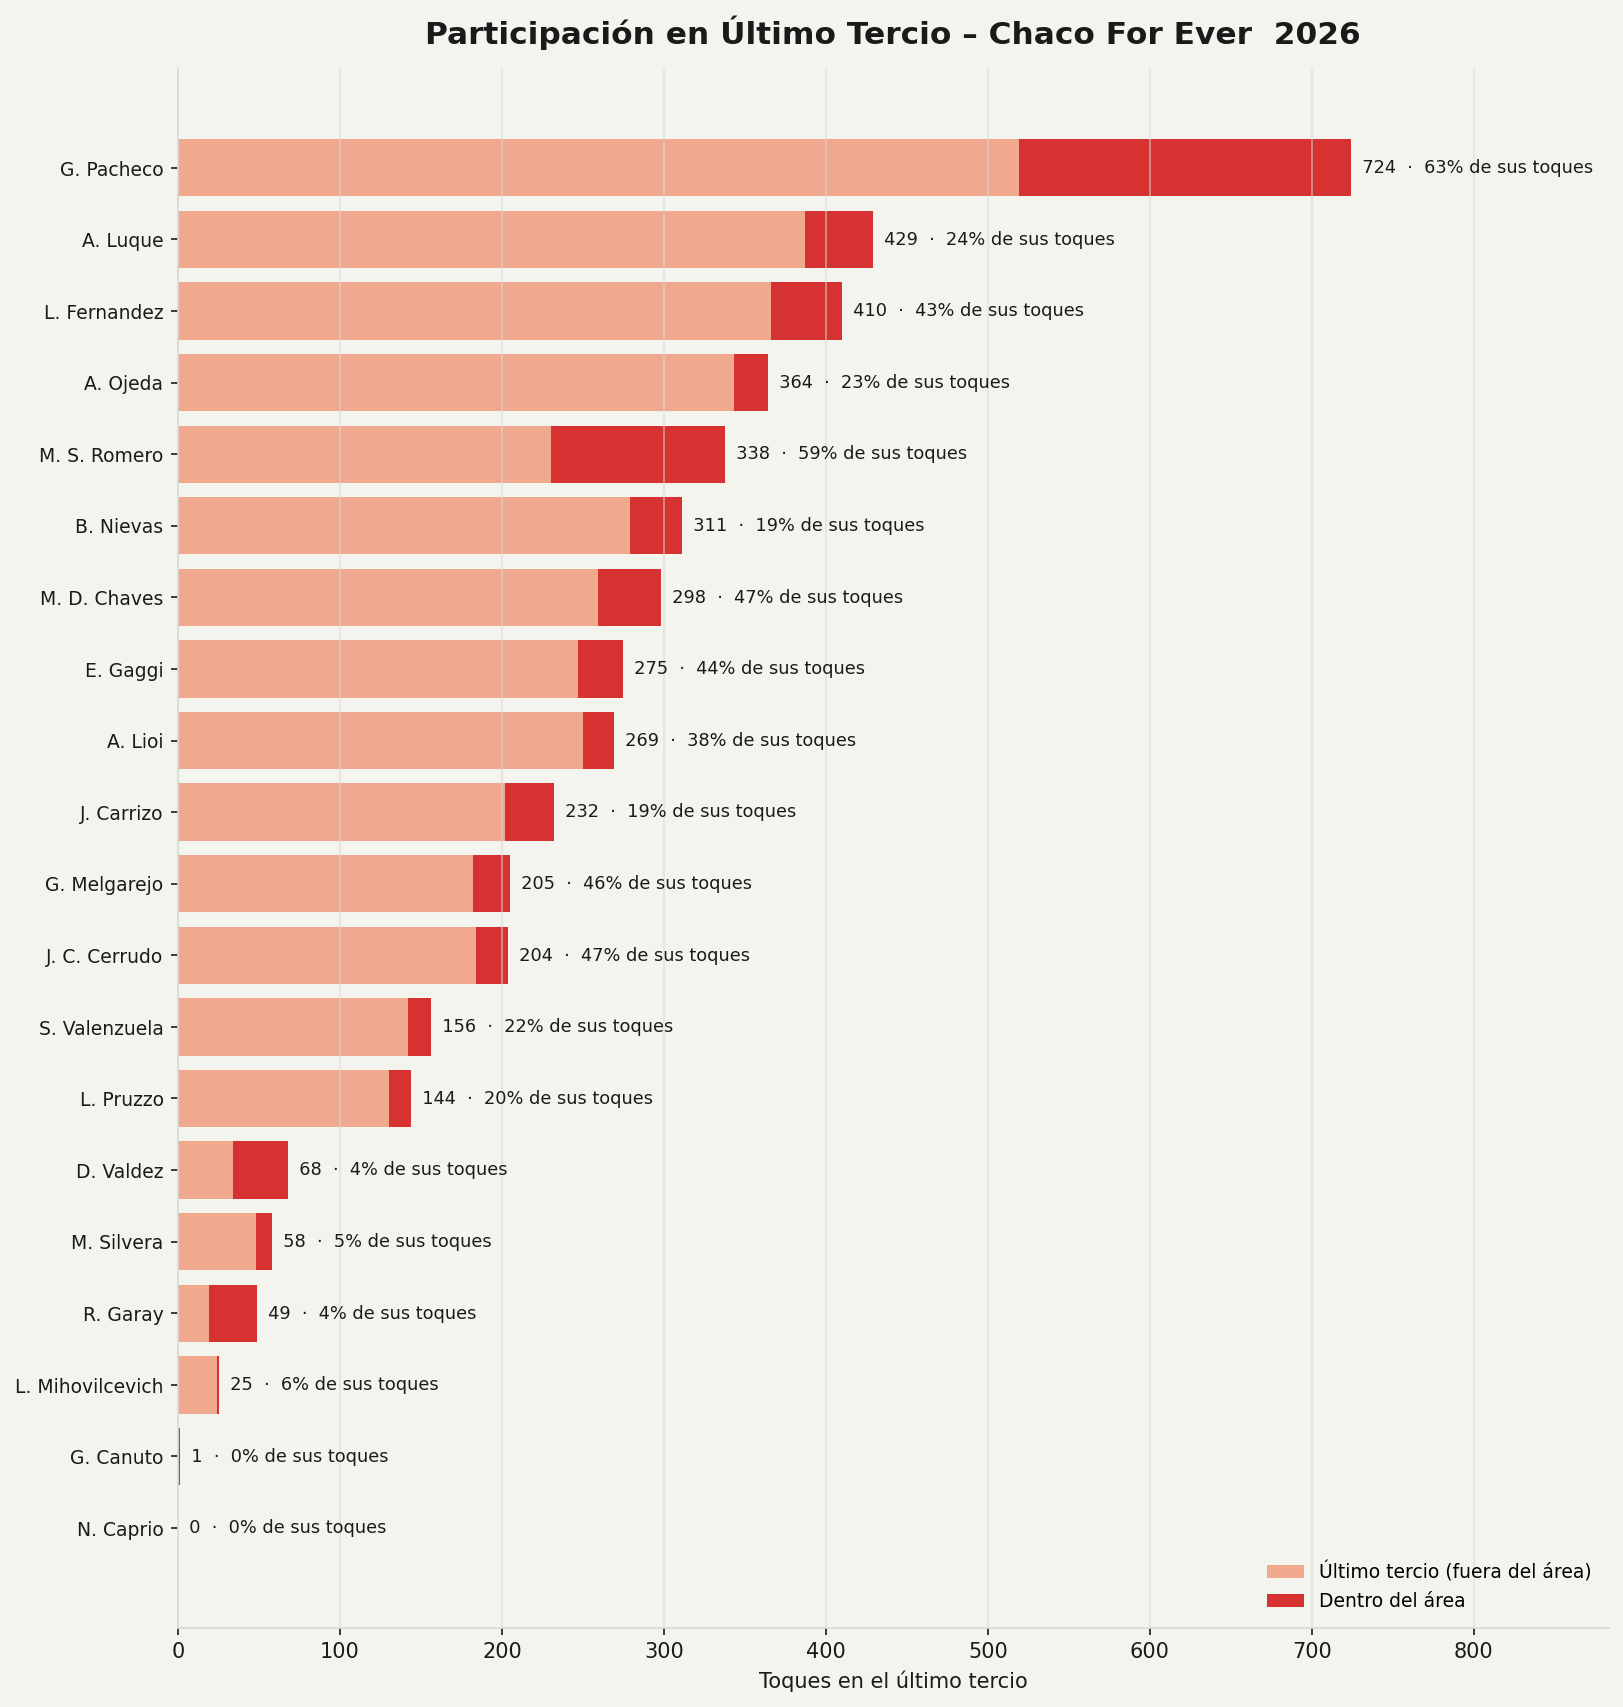

✅ toques_ultimo_tercio.png  (20 jugadores)


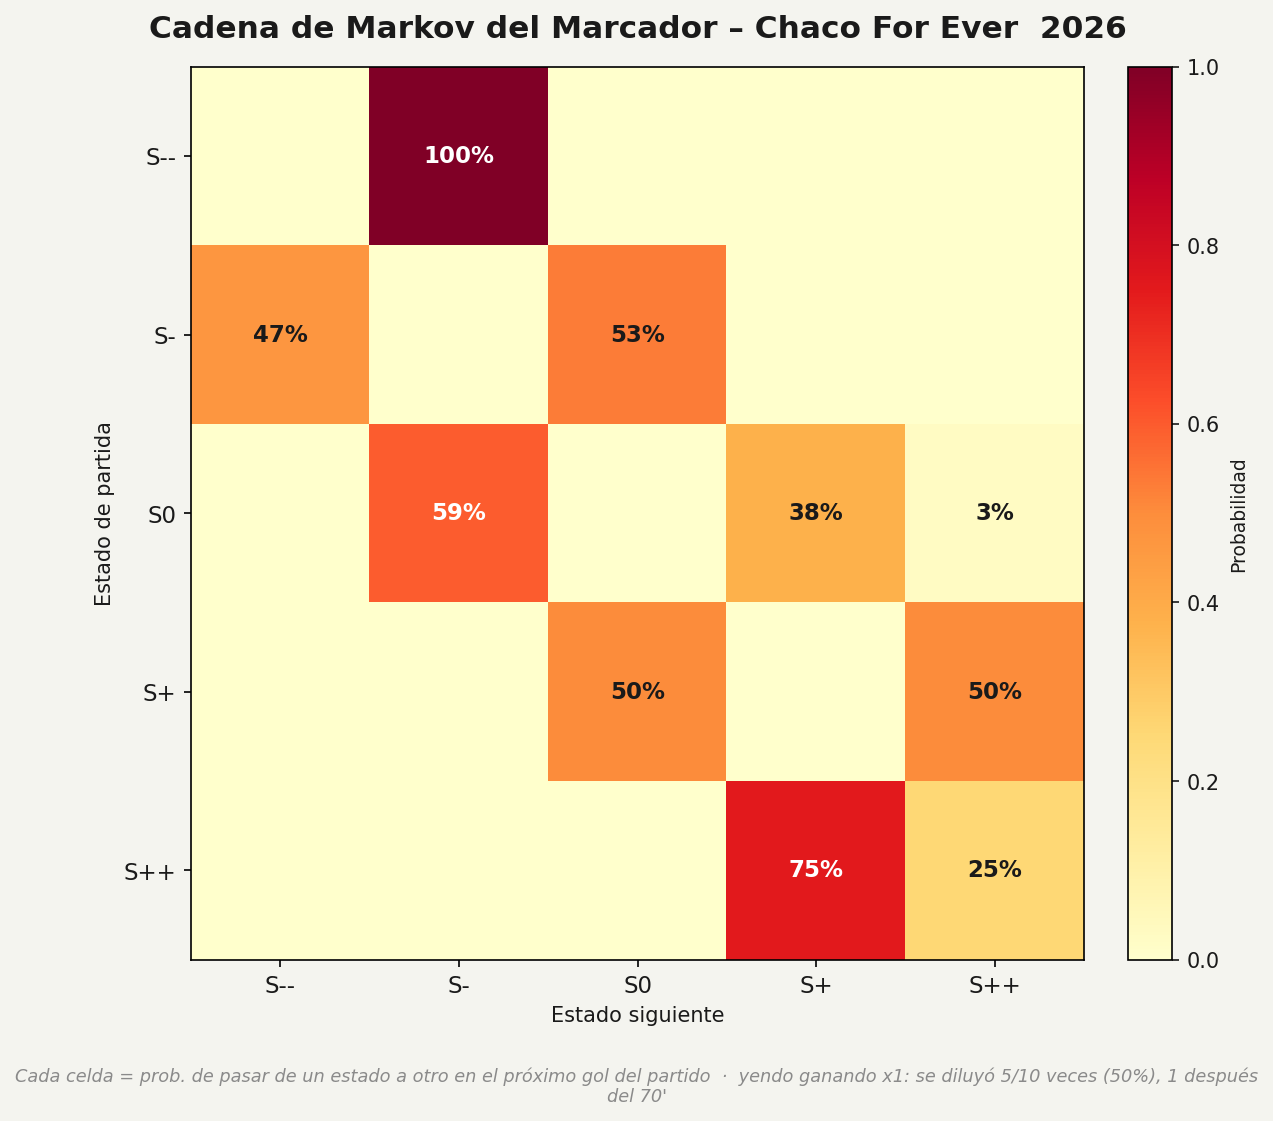

✅ markov_marcador.png


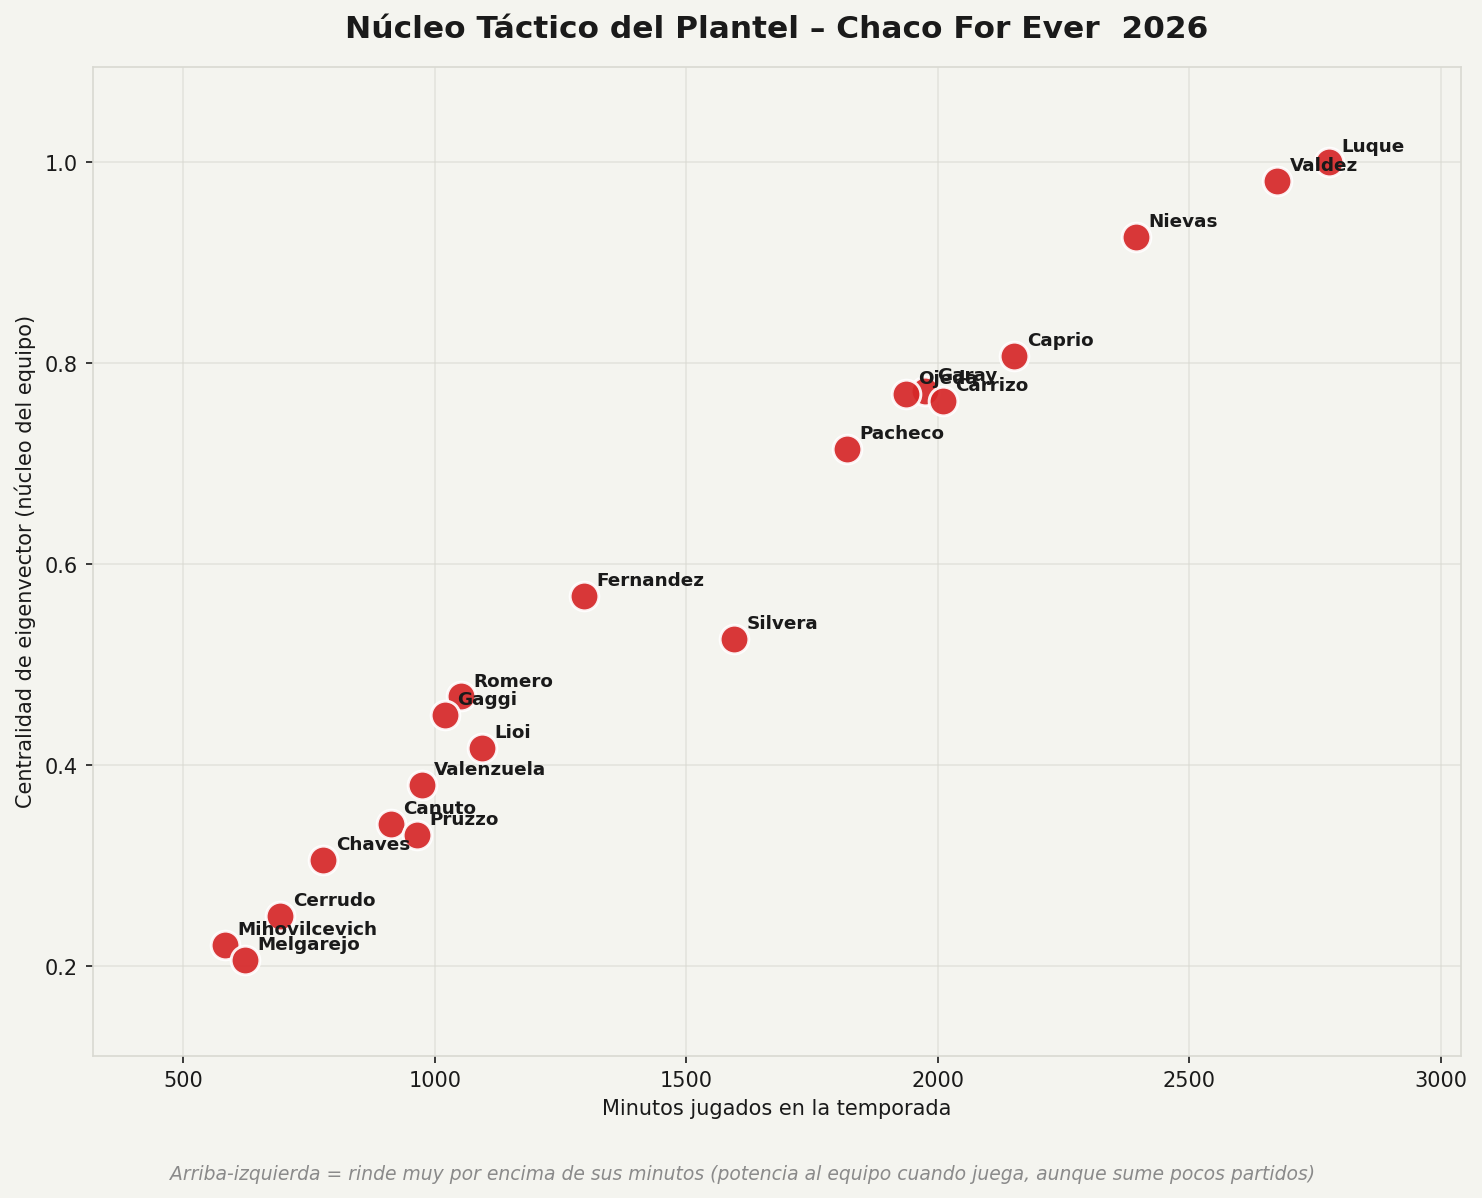

✅ nucleo_tactico.png


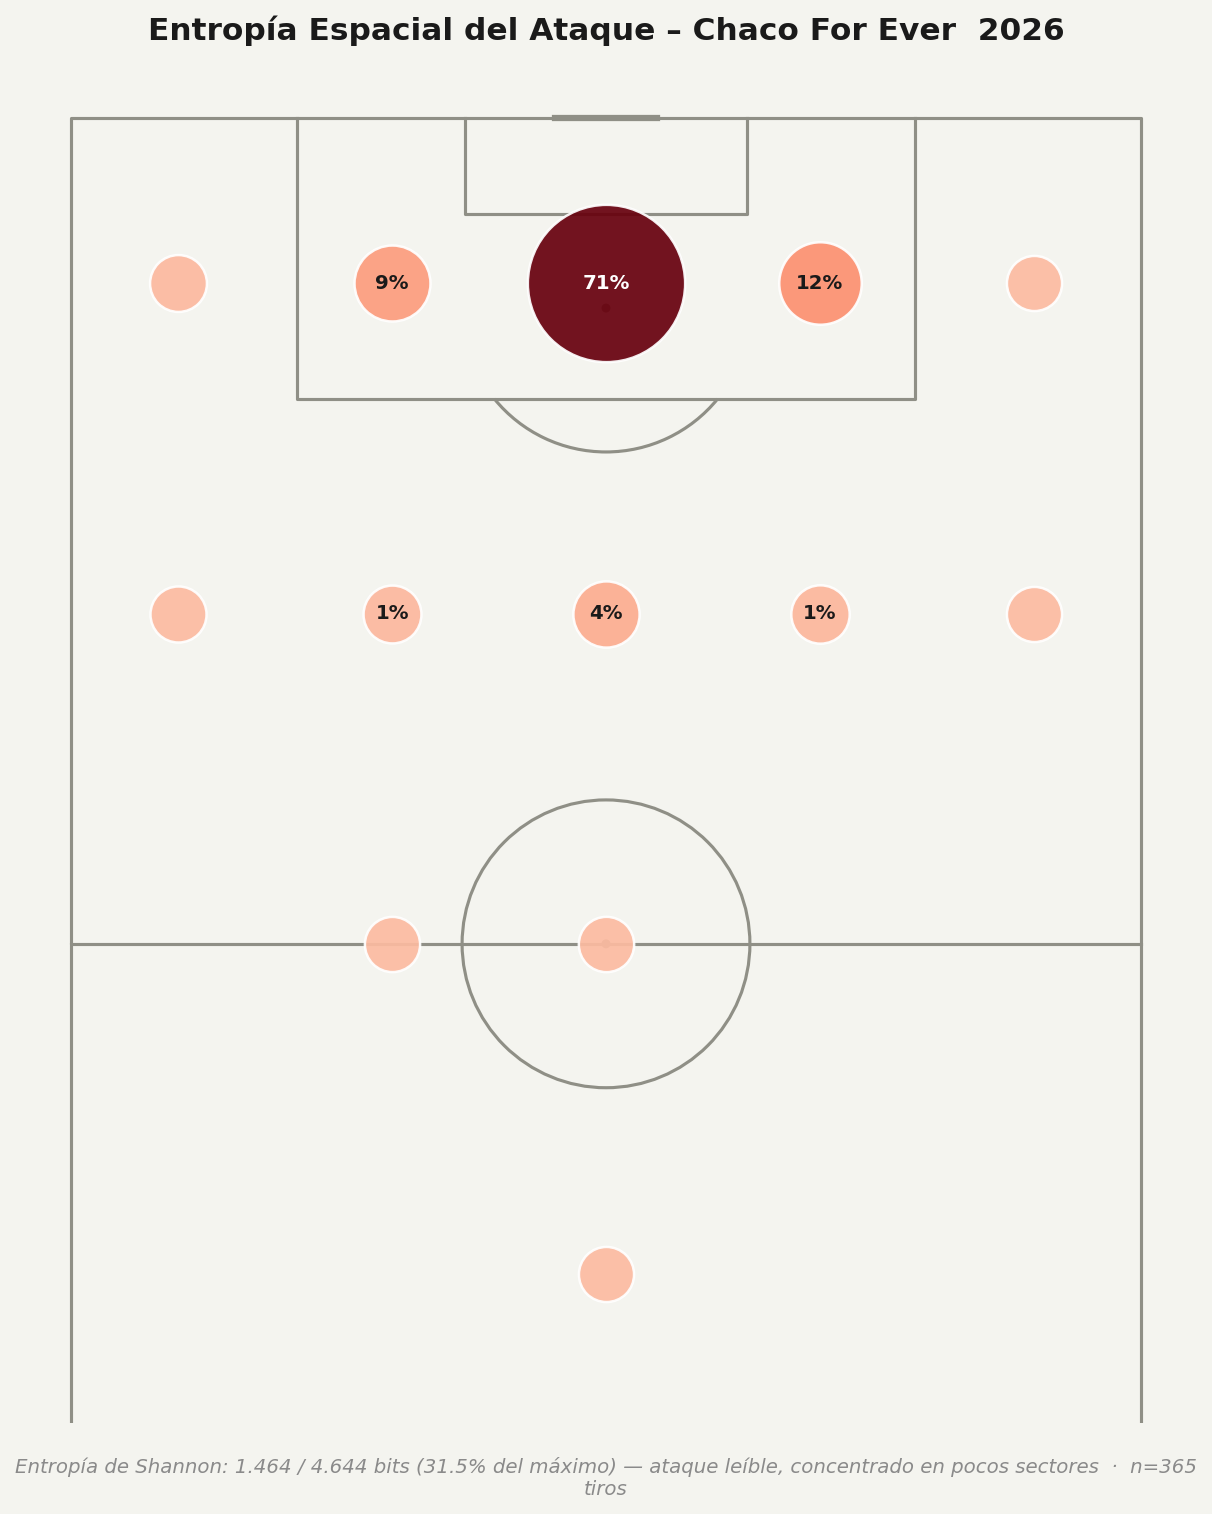

✅ entropia_tiros.png  (H=1.464 / 4.644 bits, 31.5% del máximo)


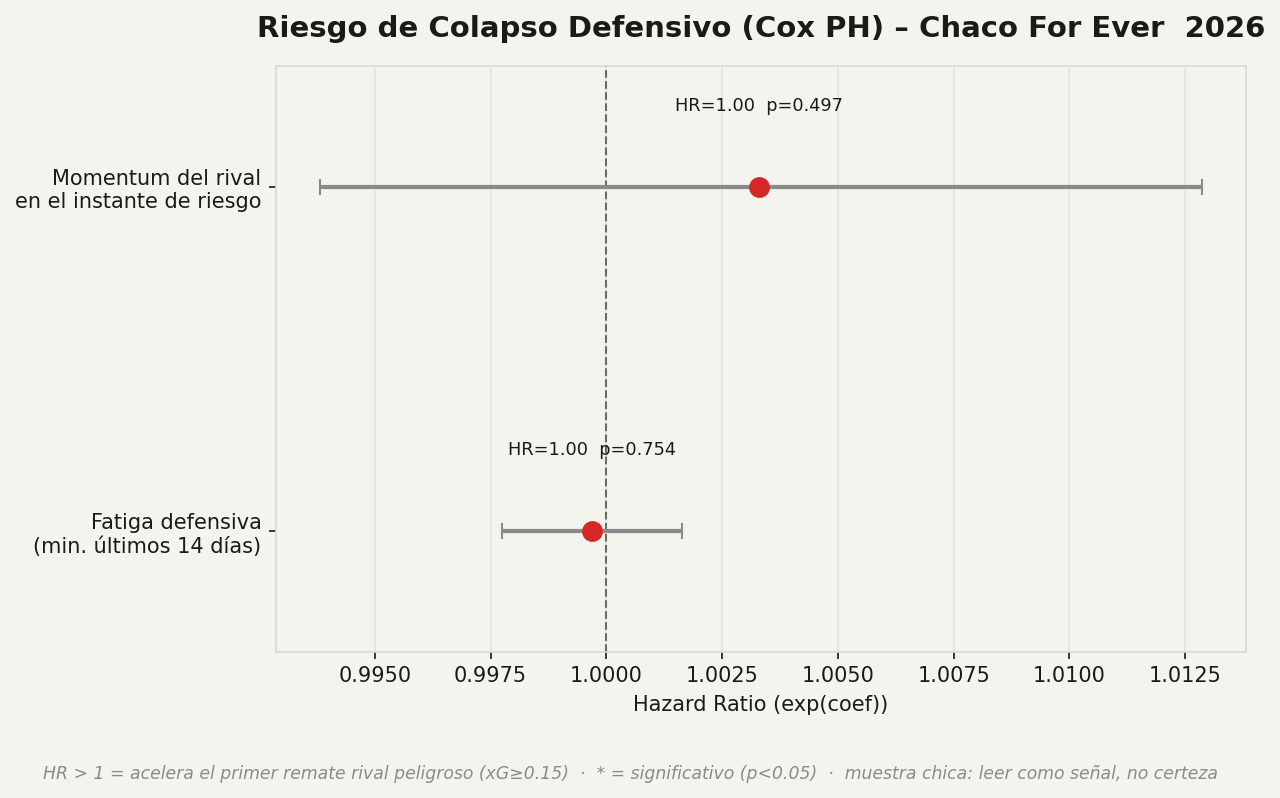

✅ riesgo_defensivo_cox.png
                   exp(coef)  exp(coef) lower 95%  exp(coef) upper 95%         p
covariate                                                                       
defensive_fatigue   0.999690             0.997752             1.001632  0.754483
momentum_at_risk    1.003293             0.993818             1.012859  0.497114


In [9]:
# ── Gráficos nuevos de temporada (doc IDEAS_NUEVAS, sección 2) ──
import pandas as pd

# Las redes / núcleo táctico / toques usan RELEVANTES_ACTUALES (sacan a los que
# ya no están en el club: características del equipo de HOY). El resto usa
# RELEVANTES o umbrales bajos, para que los refuerzos de mitad de año no
# desaparezcan por no tener minutos acumulados de todo el año.

# 1) Red de minutos compartidos — quién juega junto y cómo le fue al equipo en
#    esos minutos. Nodo ∝ minutos; cuerda ∝ minutos juntos; color = dif de gol/90.
nodes, edges = shared_minutes_network(match_keys_with_data, BASE_DIR, players=RELEVANTES_ACTUALES)
if not nodes.empty:
    p = os.path.join(PLOTS_DIR, 'red_minutos_compartidos.png')
    plot_shared_minutes_network(nodes, edges, season=SEASON, min_edge_minutes=120,
                                top_edges=28, save_path=p)
    show(p)
    print(f'✅ red_minutos_compartidos.png  ({len(nodes)} jugadores, {len(edges)} duplas)')
    nuevos_en_red = sorted(set(nodes['player_name']) & set(refuerzos['player'])) if not refuerzos.empty else []
    if nuevos_en_red:
        print(f'   incorporaciones en la red: {", ".join(nuevos_en_red)}')

# 1b) Duplas asociativas — la dupla se arma por CERCANÍA EN CANCHA + VOLUMEN DE
#     PASES (posición promedio real y pases acertados reales). Se sacan los que
#     ya no están en el club.
pa_nodes, pa_edges = pass_association_network(match_keys_with_data, BASE_DIR, min_matches=4)
pa_nodes = sin_fuera(pa_nodes, ['player_name'])
pa_edges = sin_fuera(pa_edges, ['p1', 'p2'])
if not pa_nodes.empty:
    p = os.path.join(PLOTS_DIR, 'duplas_asociativas.png')
    plot_pass_association_network(pa_nodes, pa_edges, season=SEASON, min_edge_matches=4,
                                  top_edges=26, save_path=p)
    show(p)
    print(f'✅ duplas_asociativas.png  ({len(pa_nodes)} jugadores, {len(pa_edges)} duplas)')

# 2) Mapa de tiros CONCEDIDOS de la temporada.
conc = []
for mk in match_keys_with_data:
    sp = os.path.join(BASE_DIR, mk, 'shotmap_clean.csv')
    if os.path.exists(sp):
        df_s = pd.read_csv(sp)
        conc.append(df_s[df_s['isHome'] != is_home_match(mk)])
if conc:
    df_conc = pd.concat(conc, ignore_index=True)
    p = os.path.join(PLOTS_DIR, 'tiros_concedidos_temporada.png')
    plot_shotmap_4grid(df_conc, team_label='Tiros Concedidos',
                       title=f'Tiros Concedidos – Temporada {SEASON}', save_path=p)
    show(p)
    print('✅ tiros_concedidos_temporada.png')

# 3) Forma reciente (media móvil de 5 partidos).
p = os.path.join(PLOTS_DIR, 'forma_reciente.png')
plot_recent_form(season_df, window=5, season=SEASON, save_path=p)
show(p)
print('✅ forma_reciente.png')

# 4) Local vs Visitante.
p = os.path.join(PLOTS_DIR, 'local_vs_visitante.png')
plot_home_away_panel(season_df, season=SEASON, save_path=p)
show(p)
print('✅ local_vs_visitante.png')

# 5) Disciplina acumulada — amarillas/rojas por jugador en la temporada.
p = os.path.join(PLOTS_DIR, 'disciplina.png')
plot_discipline(player_df, season=SEASON, suspension_at=5, save_path=p)
show(p)
print('✅ disciplina.png')

# 6) Calendario de carga — minutos por jugador a lo largo del año. Plantel
#    completo (registro de cómo se repartieron los minutos).
mat, meta = load_calendar(match_keys_with_data, BASE_DIR, players=RELEVANTES)
p = os.path.join(PLOTS_DIR, 'calendario_carga.png')
plot_load_calendar(mat, meta, season=SEASON, save_path=p)
show(p)
print(f'✅ calendario_carga.png  ({len(mat)} jugadores)')

# 7) Red de asistencias — quién habilita a quién. Se sacan los que ya no están.
an, ae = assists_network(match_keys_with_data, BASE_DIR)
an = sin_fuera(an, ['player'])
ae = sin_fuera(ae, ['assister', 'scorer'])
if not an.empty:
    p = os.path.join(PLOTS_DIR, 'red_asistencias.png')
    plot_assists_network(an, ae, season=SEASON, save_path=p)
    show(p)
    print(f'✅ red_asistencias.png  ({len(an)} jugadores, {len(ae)} conexiones)')

# 8) Amenaza por tipo de jugada.
threat = threat_by_situation(match_keys_with_data, BASE_DIR)
if not threat.empty:
    p = os.path.join(PLOTS_DIR, 'amenaza_por_jugada.png')
    plot_threat_by_situation(threat, season=SEASON, save_path=p)
    show(p)
    print('✅ amenaza_por_jugada.png')

# 9) xG según estado del marcador.
xgst = xg_by_score_state(match_keys_with_data, BASE_DIR)
if not xgst.empty:
    p = os.path.join(PLOTS_DIR, 'xg_por_estado_marcador.png')
    plot_xg_by_score_state(xgst, season=SEASON, save_path=p)
    show(p)
    print('✅ xg_por_estado_marcador.png')

# 10) Toques en último tercio por jugador (RELEVANTES_ACTUALES).
ft = final_third_touches(match_keys_with_data, BASE_DIR,
                         top_n=len(RELEVANTES_ACTUALES) or 14, players=RELEVANTES_ACTUALES)
if not ft.empty:
    p = os.path.join(PLOTS_DIR, 'toques_ultimo_tercio.png')
    plot_final_third_touches(ft, season=SEASON, save_path=p)
    show(p)
    print(f'✅ toques_ultimo_tercio.png  ({len(ft)} jugadores)')

# 11) Cadena de Markov del estado del marcador.
markov_matrix, markov_trans = markov_game_state(match_keys_with_data, BASE_DIR)
p = os.path.join(PLOTS_DIR, 'markov_marcador.png')
plot_markov_transitions(markov_matrix, markov_trans, season=SEASON, save_path=p)
show(p)
print('✅ markov_marcador.png')

# 12) Núcleo táctico (eigenvector) — sobre el grafo de minutos (ya sin los que
#     se fueron), ponderado por el rendimiento neto de cada dupla.
eigen_nodes = eigenvector_centrality_network(nodes, edges, min_minutes=180)
p = os.path.join(PLOTS_DIR, 'nucleo_tactico.png')
plot_eigen_centrality(eigen_nodes, season=SEASON, save_path=p)
show(p)
print('✅ nucleo_tactico.png')

# 13) Entropía de Shannon del shotmap propio.
entropy_stats = shot_entropy(match_keys_with_data, BASE_DIR)
if entropy_stats['n_shots']:
    p = os.path.join(PLOTS_DIR, 'entropia_tiros.png')
    plot_shot_entropy(entropy_stats, season=SEASON, save_path=p)
    show(p)
    print(f"✅ entropia_tiros.png  (H={entropy_stats['entropy']} / "
         f"{entropy_stats['max_entropy']} bits, {entropy_stats['pct_of_max']}% del máximo)")

# 14) Riesgo de colapso defensivo (Cox). Muestra chica: señal, no certeza.
surv = build_defensive_survival_dataset(match_keys_with_data, BASE_DIR)
if surv['event'].sum() >= 2 and surv['defensive_fatigue'].std() > 0:
    cph = fit_defensive_hazard_model(surv)
    p = os.path.join(PLOTS_DIR, 'riesgo_defensivo_cox.png')
    plot_defensive_hazard(cph, season=SEASON, save_path=p)
    show(p)
    print('✅ riesgo_defensivo_cox.png')
    print(cph.summary[['exp(coef)', 'exp(coef) lower 95%', 'exp(coef) upper 95%', 'p']]
         .to_string())
else:
    print('⚠️  Cox omitido: pocos eventos de riesgo o sin variación en la fatiga.')


## 5. Análisis de cambios en la temporada

In [10]:
subs_df = substitution_analysis(match_keys_with_data, BASE_DIR)
if not subs_df.empty:
    print(f'Total cambios de Chaco: {len(subs_df)}')
    avg_min = subs_df['minute'].mean()
    print(f'Minuto promedio de primer cambio: {avg_min:.1f}\'')
    print('\nJugadores más introducidos como suplentes:')
    print(subs_df['player_in'].value_counts().head(10).to_string())

Total cambios de Chaco: 160
Minuto promedio de primer cambio: 66.7'

Jugadores más introducidos como suplentes:
player_in
M. D. Chaves     16
G. Melgarejo     14
A. Lioi          14
S. Valenzuela    11
F. Moreno         9
A. Alonso         8
L. Espejo         8
B. Guerra         7
I. Enriquez       7
G. Pacheco        7


## 6. Perfiles individuales — Pizza y Radar
Percentiles por-90 de cada jugador de Chaco contra el **pool** de todos los
jugadores que aparecen en los partidos scrapeados (Chaco + rivales = referencia
de la Primera Nacional).

Se le genera pizza a **todo el plantel**, sin piso de minutos. En lugar de
esconder al que jugó poco, cada gráfico lleva impresos los minutos jugados, los
partidos y un cartel de tamaño de muestra:

| Minutos | Cartel |
|---|---|
| 900+ | muestra amplia |
| 450–899 | muestra media |
| 180–449 | MUESTRA CHICA – leer con cuidado |
| menos de 180 | MUESTRA MUY CHICA – no concluyente |

Debajo va la fecha de debut y qué porcentaje de los minutos disponibles desde
entonces jugó — así se distingue al refuerzo que juega todo desde que llegó del
suplente que entra dos minutos por fecha, aunque los dos tengan pocos minutos
acumulados.

Los percentiles se calculan siempre contra la misma referencia (jugadores con
90'+), así la escala no cambia de un pizza a otro.

In [11]:
# Pool de REFERENCIA (Chaco + rivales) con métricas por-90. Es la vara contra
# la que se calculan los percentiles, y se mantiene en 90'+ para que la escala
# sea la misma en todos los pizzas.
#
# player_pool agrupa por (jugador, EQUIPO): un lineup trae los dos equipos del
# partido, así que un homónimo o alguien que cambió de club a mitad de año
# (A. Alonso vino de Gimnasia Jujuy, G. Ramirez de All Boys) tendría sus minutos
# de los dos clubes sumados. Con el corte por equipo, chaco_pool toma SOLO los
# partidos con Chaco For Ever en 2026.
POOL_MIN_MINUTES = 90

pool = player_pool(match_keys_with_data, BASE_DIR, min_minutes=POOL_MIN_MINUTES)
print(f'Pool de referencia: {len(pool)} jugadores ({int(pool["is_chaco"].sum())} de Chaco)')

pool_todos = player_pool(match_keys_with_data, BASE_DIR, min_minutes=1)

PIZZA_DIR = os.path.join(PLOTS_DIR, 'jugadores')
os.makedirs(PIZZA_DIR, exist_ok=True)

# SOLO las filas de Chaco (una por jugador, con sus minutos/partidos de Chaco).
chaco_pool = pool_todos[pool_todos['is_chaco']].sort_values('minutes', ascending=False)
avail_idx = avail.set_index('player')

generados = []
for _, jugador in chaco_pool.iterrows():
    nombre = jugador['player_name']
    # Percentiles: se busca al jugador en chaco_pool (su fila de Chaco) y se
    # compara contra la referencia de 90'+ — misma escala para todos.
    pcts = player_percentiles(nombre, chaco_pool, reference_df=pool,
                              team_name=jugador['team_name'])
    if not pcts:
        continue

    # Nota al pie: fecha de debut y % de los minutos disponibles desde entonces.
    nota = ''
    if nombre in avail_idx.index:
        a = avail_idx.loc[nombre]
        fecha = pd.to_datetime(a['fecha_debut']).strftime('%d/%m')
        if a['es_incorporacion']:
            nota = (f"Debutó el {fecha} · jugó el {a['pct_disponible']:.0f}% "
                    f"de los minutos disponibles desde entonces")
        else:
            nota = (f"En el plantel desde la fecha 1 · jugó el "
                    f"{a['pct_disponible']:.0f}% de los minutos de la temporada")

    fig = plot_player_pizza(nombre, pcts, context_label=f'Temporada {SEASON}',
                            minutes=jugador['minutes'], matches=jugador['matches'],
                            sample_note=nota)
    if fig:
        safe = nombre.replace(' ', '_').replace('.', '')
        save_fig(fig, os.path.join(PIZZA_DIR, f'pizza_{safe}.png'))
        generados.append(nombre)

print(f'✅ {len(generados)} pizzas generadas en graficos/jugadores/ (todo el plantel, solo minutos con Chaco 2026)')

resumen = chaco_pool[['player_name', 'matches', 'minutes']].merge(
    avail[['player', 'fecha_debut', 'pct_disponible']],
    left_on='player_name', right_on='player', how='left').drop(columns='player')
resumen['muestra'] = pd.cut(resumen['minutes'], [-1, 180, 450, 900, 1e9],
                            labels=['muy chica', 'chica', 'media', 'amplia'])
print(resumen.to_string(index=False))

sin_pizza = sorted(set(chaco_pool['player_name']) - set(generados))
if sin_pizza:
    print()
    print(f'Sin pizza (sin datos suficientes): {", ".join(sin_pizza)}')
nunca_jugaron = sorted(set(avail.loc[avail['minutos'] <= 0, 'player']))
if nunca_jugaron:
    print(f'Fueron al banco pero nunca entraron: {", ".join(nunca_jugaron)}')


Pool de referencia: 233 jugadores (32 de Chaco)


✅ 36 pizzas generadas en graficos/jugadores/ (todo el plantel, solo minutos con Chaco 2026)
     player_name  matches  minutes fecha_debut  pct_disponible   muestra
        A. Luque       33   2778.0  2026-02-14            90.8    amplia
       D. Valdez       32   2675.0  2026-02-14            87.4    amplia
       B. Nievas       33   2394.0  2026-02-14            78.2    amplia
       N. Caprio       34   2152.0  2026-02-14            70.3    amplia
      J. Carrizo       30   2010.0  2026-02-21            67.7    amplia
        R. Garay       28   1974.0  2026-02-14            64.5    amplia
        A. Ojeda       27   1937.0  2026-02-14            63.3    amplia
      G. Pacheco       28   1820.0  2026-02-14            59.5    amplia
      M. Silvera       31   1595.0  2026-02-14            52.1    amplia
    L. Fernandez       16   1297.0  2026-07-07            90.1    amplia
         A. Lioi       32   1093.0  2026-02-14            35.7    amplia
    M. S. Romero       13   1052

In [12]:
# Radar clásico: compara DOS jugadores en sus métricas por 90'.
# Conviene comparar jugadores de rol parecido — un arquero (position 'G') contra
# un delantero no dice nada, así que por defecto excluimos arqueros.
field_pool = chaco_pool[chaco_pool['position'] != 'G']

# Cambiá los nombres acá — deben existir en el pool (ver lista de arriba)
PLAYER_A = field_pool.iloc[0]['player_name'] if len(field_pool) > 0 else None
PLAYER_B = field_pool.iloc[1]['player_name'] if len(field_pool) > 1 else None

if PLAYER_A and PLAYER_B:
    print(f'Comparando: {PLAYER_A}  vs  {PLAYER_B}')
    comp = compare_players(PLAYER_A, PLAYER_B, pool)
    if comp:
        fig = plot_players_radar(comp)
        if fig:
            safe = f"radar_{PLAYER_A.replace(' ','_')}_vs_{PLAYER_B.replace(' ','_')}".replace('.','')
            save_fig(fig, os.path.join(PIZZA_DIR, f'{safe}.png'))
            print(f'✅ Radar {PLAYER_A} vs {PLAYER_B} guardado en graficos/jugadores/')

Comparando: A. Luque  vs  D. Valdez


✅ Radar A. Luque vs D. Valdez guardado en graficos/jugadores/


## 6. Generar informe narrativo de temporada (Claude)

In [13]:
# Informe narrativo de temporada con un modelo de lenguaje.
# La key se toma del .env (NVIDIA_API_KEY) al importar config — no hace falta
# pegarla acá. Proveedor en config.REPORT_PROVIDER (por defecto "nvidia" = GRATIS).
if GENERATE_REPORT:
    report = season_report(
        season_stats=stats,
        season_df=season_df,
        player_season_df=player_df,
        season=SEASON,
    )
    print('\n' + report[:600] + '...')
else:
    print('GENERATE_REPORT=False — informe omitido.')

GENERATE_REPORT=False — informe omitido.
